In [1]:
import os
import json
import pickle
import numpy as np
import pandas as pd
from itertools import chain
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from morph_utils.templates import load_layer_template

from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
from scikit_posthocs import posthoc_dunn

import anndata as ad
import operator

# Core utilities
from core_utils import get_tx_order_dict, get_seaad_colors

# Morphology visualization
from morphology_utils import (
    plot_dendrite_depth_profiles_swb, plot_axon_depth_profiles_swb, plot_prop_for_mets_swb,
    plot_dendrite_depth_profiles_subclass, plot_axon_depth_profiles_subclass,
    plot_morph_lineup_swb, plot_morpho_gallery, plot_distal_apicals, process_distal_apicals,
    overlay_morphologies, plot_subclass_hairballs, plot_subclass_heatmap, add_swc_paths
)

# Electrophysiology visualization
from electrophysiology_utils import (
    plot_ephys_subthresh, process_fi_curves, plot_avg_fi_for_mets,
    plot_ap_subclass, plot_ap_ttype, plot_ephys_gallery
)

# Spatial and embedding visualization
from spatial_embedding_utils import (
    plot_spatial_slice, plot_spatial_density_kde, plot_ref_umap_crop,
    plot_ref_umap, plot_umap
)

# Summary statistics and metadata
from summary_stats_utils import plot_donor_lobe_counts, plot_subclass_eta2_topn, abundance_barplot

/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:255: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Functions

Params

In [2]:
#paradigm params
acute_only = False #whether to exclude all culture cells 
mark_paradigm = True #whether to have the scatter marker differentiate paradigm 
mark_paradigm_type = 'oo' #'xo', 'oo' #the type of marker if mark_paradigm == True 

In [3]:
# Transcriptomic label columns 
CLASS_COL =    'class_label_Hierarchical'
SUBCLASS_COL = 'subclass_label_Hierarchical'
CLUSTER_COL =  'cluster_label_Hierarchical'

# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260721'
if acute_only: 
    OUT_DIR = OUT_DIR / 'acute_only'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

#Metadata 
metadata_path =               DATA_ROOT / 'human'            / 'metadata' / 'human_metadata.csv'
gallery_cells =               '/root/capsule/data/human/morphology/gallery/20251010/human_excitatory_gallery_viewer_dendrite.csv'
feature_type_color_file =     DATA_ROOT / 'colors'           / 'feature_type_color_dict.json'
lobe_color_file =             DATA_ROOT / 'colors'           / 'lobe_colors.json'
paradigm_color_file =         DATA_ROOT / 'colors'           / 'paradigm_colors.json'
l23_ttype_rename_file =   DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =        DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'
ttype_to_subclass_file =  DATA_ROOT / 'formatting_dicts' / 'ttype_subclass_dict.json'
subclass_order_file =     DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'
ttype_order_file =        DATA_ROOT / 'formatting_dicts' / 'ttype_order.txt'

#Morphology 
morpho_data_dend_root =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712'
morpho_data_axon_root =      DATA_ROOT / 'human' / 'morphology' / 'axon'     / '20260715'
layer_aligned_dir =          DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'
heatmap_dir =                '/root/capsule/data/human/morphology/kde/20251010'
morpho_feature_rename_file = DATA_ROOT / 'formatting_dicts' / 'morpho_feature_rename.csv'

#Electrophysiology
ephys_path =                '/root/capsule/data/human/electrophysiology/temp-10151008_data/20251008_ephys_features_imputed.csv'
ephys_subthresh_dir =       '/root/capsule/data/human/electrophysiology/20250801/ephys_subthresh'
ephys_fi_file =             '/root/capsule/data/human/electrophysiology/temp-10151008_data/20251008_ephys_fi_curve_data.csv'
ephys_ap_file =             '/root/capsule/data/human/electrophysiology/temp-20251007_ap_phase_data/human_exc_ap_phase_data.npy'
svg_root =                  '/root/capsule/data/human/electrophysiology/temp-20250801/ephys_ap_svgs'
ephys_feature_rename_file = DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'

#UMAPs
reference_umap_file = '/root/capsule/data/human/reference/20250710/FACS_patchseq_QC_and_UMAP.csv'
m_umap_file =         '/root/capsule/data/human/umaps/20250815/morphology/human_excitatory_umap_2d_nn15_md0.1_all.csv'
e_umap_file =         '/root/capsule/data/human/umaps/20250815/electrophysiology/human_excitatory_ephys_umap_2d_nn15_md0.1_withDepth.csv'
me_umap_file =        '/root/capsule/data/human/umaps/20250815/morphoelectric/human_excitatory_umap_2d_nn15_md0.1_all.csv'

#MERFISH 
abundance_path =                   '/root/capsule/data/human/reference/20250627/SEAAD_ref_counts.csv'
isodepth_file =                    '/root/capsule/data/human/spatial/20250624/20250624_isodepths.csv'
spatial_slice_file =               '/root/capsule/data/human/spatial/20250711/H1930002Cx46MTG202007105_subset_section_qcd.h5ad'
spatial_slice_layer_overlay_file = '/root/capsule/data/human/spatial/20251028/slice_crop_layer_overlay.png'


Load data

In [ ]:
with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

with open(, "r") as f:
    ttype_to_subclass_dict = json.load(f)

#ephys feature rename dict 
ephys_feature_rename_df = pd.read_csv(ephys_feature_rename_file)
ephys_feature_rename_dict = dict(zip(ephys_feature_rename_df.old_feature_name, ephys_feature_rename_df.new_feature_name))

#morpho feature rename dict 
morpho_feature_rename_df = pd.read_csv(morpho_feature_rename_file)
morpho_feature_rename_dict = dict(zip(morpho_feature_rename_df.old_feature_name, morpho_feature_rename_df.alt_new_feature_name))

# SEA-AD mapping colors
SEAAD_COLORS = get_seaad_colors()

#feature type colors (apical, basal, soma, etc)
with open(feature_type_color_file, "r") as f:
    feature_type_color_dict = json.load(f)
morpho_feature_color_dict = dict(zip(morpho_feature_rename_df.alt_new_feature_name, [feature_type_color_dict[t.strip()] for t in morpho_feature_rename_df.type.tolist()]))


metadata = pd.read_csv(metadata_path, encoding='latin1')
metadata[subclass_col] = metadata[subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
metadata[cluster_col] = metadata[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
metadata[cluster_col] = metadata[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata[cluster_col].map(ttype_to_layer_dict)
#split Layer 2 and 3 subclass
metadata["layer_subclass"] = metadata.apply(lambda row: "L2 IT" if row["layer"] == 'Layer 2' else ("L3 IT" if row["layer"] == 'Layer 3' else row[subclass_col]), axis=1)
metadata["layer_split"] = metadata.apply(lambda row: "L2" if row["layer"] == 'Layer 2' else ("L3" if row["layer"] == 'Layer 3' else row['layer']), axis=1)

metadata_morph = pd.read_csv(os.path.join(morpho_data_root, 'metadata.csv'))
metadata_morph[subclass_col] = metadata_morph[subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
metadata_morph[cluster_col] = metadata_morph[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
metadata_morph[cluster_col] = metadata_morph[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata_morph['layer'] = metadata_morph[cluster_col].map(ttype_to_layer_dict)
#split Layer 2 and 3 subclass
metadata_morph["layer_subclass"] = metadata_morph.apply(lambda row: "L2 IT" if row["layer"] == 'Layer 2' else ("L3 IT" if row["layer"] == 'Layer 3' else row[subclass_col]), axis=1)
metadata_morph["layer_split"] = metadata_morph.apply(lambda row: "L2" if row["layer"] == 'Layer 2' else ("L3" if row["layer"] == 'Layer 3' else row['layer']), axis=1)

metadata_morph_axon = pd.read_csv(os.path.join(morpho_data_root_axon, 'metadata.csv'), encoding='latin1')
metadata_morph_axon[subclass_col] = metadata_morph_axon[subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
metadata_morph_axon[cluster_col] = metadata_morph_axon[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
metadata_morph_axon[cluster_col] = metadata_morph_axon[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata_morph['has_axon'] = metadata_morph.specimen_id.isin(metadata_morph_axon.specimen_id.astype(int).tolist())

#dendrite histograms
aligned_histogram = pd.read_csv(os.path.join(morpho_data_root, 'AlignedHistogram.csv'), index_col=0)
aligned_histogram *= 1.144 # approx. scaling to microns
all_cols = sorted(aligned_histogram.columns, key=natural_sort_key)
basal_cols = [c for c in all_cols if c.startswith("3_")]
apical_cols = [c for c in all_cols if c.startswith("4_")]
aligned_soma_depths = pd.read_csv(os.path.join(morpho_data_root, 'AlignedSomaDepths.csv'))
raw_feature_wide = pd.read_csv(os.path.join(morpho_data_root, 'RawFeatureWide.csv'))
raw_feature_wide = raw_feature_wide.rename(columns=morpho_feature_rename_dict) #rename feature names to be more interpretable

#axon histograms
aligned_histogram_axon = pd.read_csv(os.path.join(morpho_data_root_axon, 'AlignedHistogram.csv'), index_col=0)
aligned_histogram_axon *= 1.144 # approx. scaling to microns
all_cols = sorted(aligned_histogram_axon.columns, key=natural_sort_key)
axon_cols = [c for c in all_cols if c.startswith("2_")]
aligned_soma_depths_axon = pd.read_csv(os.path.join(morpho_data_root_axon, 'AlignedSomaDepths.csv'))
raw_feature_wide_axon = pd.read_csv(os.path.join(morpho_data_root_axon, 'RawFeatureWide.csv'))
raw_feature_wide_axon = raw_feature_wide_axon.rename(columns=morpho_feature_rename_dict)


ephys_data = pd.read_csv(ephys_path, index_col = 'specimen_id')
ephys_data = ephys_data.rename(columns=ephys_feature_rename_dict) #rename feature names to be more interpretable
ephys_feature_cols = [x for x in ephys_data.columns if not x.endswith('_qc') and not x.startswith('failed') and not x in ['cell_name', 'ephys?', 'ephys notes', 'specimen_name', subclass_col, 'feature_count']]
ephys_data = ephys_data[ephys_feature_cols]
metadata_ephys = pd.read_csv(metadata_path, encoding='latin1') #TODO can shift code so we don't have this redundant metadata copy
metadata_ephys[subclass_col] = metadata_ephys[subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
metadata_ephys[cluster_col] = metadata_ephys[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
metadata_ephys[cluster_col] = metadata_ephys[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata_ephys['layer'] = metadata_ephys[cluster_col].map(ttype_to_layer_dict)
#split Layer 2 and 3 subclass
metadata_ephys["layer_subclass"] = metadata_ephys.apply(lambda row: "L2 IT" if row["layer"] == 'Layer 2' else ("L3 IT" if row["layer"] == 'Layer 3' else row[subclass_col]), axis=1)
metadata_ephys["layer_split"] = metadata_ephys.apply(lambda row: "L2" if row["layer"] == 'Layer 2' else ("L3" if row["layer"] == 'Layer 3' else row['layer']), axis=1)

ephys_fi_data = pd.read_csv(ephys_fi_file)

#subthreshold response
subthresh_spike_data = {}
for layer in ['L2', 'L3', 'L4', 'L5', 'L6']:
    subthresh_spike_data[layer] = np.load(os.path.join(ephys_subthresh_dir, 'subthreshold_data_{}.npy'.format(layer.replace('/','-').replace(' ', '_'))), allow_pickle=True)[()]
subthresh_metadata = pd.read_csv(os.path.join(ephys_subthresh_dir, 'subthreshold_metadata.csv'))  
subthresh_metadata['HANN_cluster_label_assignment_winner'] = subthresh_metadata['HANN_cluster_label_assignment_winner'].apply(lambda x: L23_ttype_rename_dict.get(x, x))

loaded_ephys_ap_file = np.load(ephys_ap_file, allow_pickle=True)
ephys_ap_dict = loaded_ephys_ap_file.item()
ephys_ap_dict['L2/3 IT'] = dict(zip([L23_ttype_rename_dict.get(k, k) for k in ephys_ap_dict['L2/3 IT'].keys()], ephys_ap_dict['L2/3 IT'].values()))

abundance_ref = pd.read_csv(abundance_path)
abundance_ref = abundance_ref[abundance_ref['class_label'] == 'Neuronal: Glutamatergic']
abundance_ref['supertype_frac_of_layer'] = abundance_ref['supertype_counts'] / abundance_ref.groupby('layer')['supertype_counts'].transform('sum')
abundance_ref_total_n = abundance_ref['supertype_counts'].sum()
abundance_ref['supertype_frac_of_class'] = abundance_ref['supertype_counts'].map(lambda x: x/abundance_ref_total_n)
abundance_ref['supertype'] = abundance_ref['supertype'].apply(lambda x: L23_ttype_rename_dict.get(x, x))

abundance_pseq = pd.read_csv(metadata_path, encoding='latin1')
abundance_pseq[subclass_col] = abundance_pseq[subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
abundance_pseq[cluster_col] = abundance_pseq[cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
abundance_pseq[cluster_col] = abundance_pseq[cluster_col].apply(lambda x: L23_ttype_rename_dict.get(x, x))
abundance_pseq = abundance_pseq[abundance_pseq['Transcriptomics '] == True][[subclass_col, cluster_col]]

isodepth_df = pd.read_csv(isodepth_file)
isodepth_df = isodepth_df[isodepth_df['SEAAD_Class_name'] == 'Neuronal: Glutamatergic']
isodepth_df['SEAAD_Supertype_name'] = isodepth_df['SEAAD_Supertype_name'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
spatial_slice_data = ad.read_h5ad(spatial_slice_file)
spatial_slice_data.obs['SEAAD_Supertype_name'] = spatial_slice_data.obs['SEAAD_Supertype_name'].apply(lambda x: L23_ttype_rename_dict.get(x, x))

reference_umap = pd.read_csv(reference_umap_file)
reference_umap = reference_umap[~((reference_umap['UMAP_1'] == 0) & (reference_umap['UMAP_2'] == 0))] # Filter out (0, 0) points
reference_umap['celltype'] = reference_umap['celltype'].apply(lambda x: L23_ttype_rename_dict.get(x, x))

temp = metadata_ephys[~metadata_ephys['cell_id'].isna()][['cell_id', subclass_col]]
temp['cell_id'] = temp['cell_id'].astype(int)
m_umap = pd.read_csv(m_umap_file).merge(temp, how='left', left_on='specimen_id', right_on='cell_id')
e_umap = pd.read_csv(e_umap_file).merge(temp, how='left', left_on='specimen_id', right_on='cell_id')
me_umap = pd.read_csv(me_umap_file).merge(temp, how='left', left_on='specimen_id', right_on='cell_id')

species = 'human'
layer_info, layer_labels, layer_colors = load_layer_template(species)
layers = ['L2/3/4', 'L5/6']# 'L4', 'L5', 'L6'] #'L2/3', 

with open(lobe_color_file, 'r') as f:
    lobe_colors = json.load(f)

with open(paradigm_color_file, 'r') as f:
    paradigm_colors = json.load(f)

#get transcriptomic order 
tx_order_dict = get_tx_order_dict(subclass_order_file=subclass_order_file, ttype_order_file=ttype_order_file)
TTYPE_ORDER, SUBCLASS_ORDER = get_tx_order()


c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\anndata\_core\anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Organize data

In [7]:
#data wrangling

#combine data and get la file paths 
metadata_morph_axon = metadata_morph_axon.rename(columns={"cell_id": "specimen_id", cluster_col: "t_type", subclass_col:'subclass_label'})#, "Pinned Structure and Layer": "final_structure"})
metadata_morph_axon = metadata_morph_axon[['specimen_id', 't_type', 'subclass_label','lobe']]
metadata_morph_axon['specimen_id'] = metadata_morph_axon['specimen_id'].astype('int')
# metadata_morph_axon['subclass_label'] = metadata_morph_axon['subclass_label'].replace('L5 ET_ME', 'L5 ET')

#combine data and get la file paths 
metadata_morph = metadata_morph.rename(columns={"cell_id": "specimen_id", cluster_col: "t_type", subclass_col:'subclass_label'})#, "Pinned Structure and Layer": "final_structure"})
metadata_morph = metadata_morph[['specimen_id', 't_type', 'subclass_label', 'layer_subclass', 'lobe', 'layer_split', 'has_axon']] #, 'seuratQCpass']]
metadata_morph['specimen_id'] = metadata_morph['specimen_id'].astype('int')
# metadata_morph['subclass_label'] = metadata_morph['subclass_label'].replace('L5 ET_ME', 'L5 ET')

#add layer data
metadata_morph['layer'] = metadata_morph['subclass_label'].apply(
    lambda x: next((layer for layer in ['L2/3', 'L4', 'L5', 'L6'] if x.startswith(layer)), None)
)
metadata_morph['layer_group'] = metadata_morph['layer'].map({'L2/3':'L2/3/4', 'L4':'L2/3/4', 'L5':'L5/6', 'L6': 'L5/6'})
#remove vals without a seaad mapping
metadata_morph['t_type'] = metadata_morph['t_type'].fillna('TBD')
metadata_morph['subclass_label'] = metadata_morph['subclass_label'].fillna('TBD')

#morpho features
morpho_data = metadata_morph.merge(aligned_soma_depths, how='inner', on='specimen_id')
# morpho_data = morpho_data.merge(layer_aligned_soma_depths, how='inner', on='specimen_id')
morpho_data = add_swc_paths(morpho_data, layer_aligned_dir, column_name='SWC_layer_aligned')
morpho_data_axon = metadata_morph_axon.merge(aligned_soma_depths_axon, how='inner', on='specimen_id')
morpho_data_axon = add_swc_paths(morpho_data_axon, layer_aligned_dir, column_name='SWC_layer_aligned')


morpho_data = morpho_data.merge(raw_feature_wide, how='inner', on='specimen_id') 
morpho_data_axon = morpho_data_axon.merge(raw_feature_wide_axon, how='inner', on='specimen_id') 

#sort the cells
morpho_sorted_data = morpho_data.sort_values(by=['t_type', 'soma_distance_from_pia'])

#delete columns where any vals are nan
morpho_sorted_clean_data = morpho_sorted_data.dropna(axis=1, how='all')

#combine data and get la file paths 
metadata_ephys = metadata_ephys.rename(columns={"cell_id": "specimen_id", cluster_col: "t_type", subclass_col:'subclass_label'}) 
metadata_ephys = metadata_ephys[~metadata_ephys.specimen_id.isna()]
metadata_ephys = metadata_ephys[['specimen_id', 't_type', 'subclass_label', 'layer_subclass', 'lobe', 'layer_split', 'depth_from_pia_norm', 'paradigm']] #, 'seuratQCpass']]
metadata_ephys['specimen_id'] = metadata_ephys['specimen_id'].astype(int)

#add layer data
metadata_ephys['layer'] = metadata_ephys['subclass_label'].apply(
    lambda x: next((layer for layer in ['L2/3', 'L4', 'L5', 'L6'] if x.startswith(layer)), None)
)
metadata_ephys['layer_group'] = metadata_ephys['layer'].map({'L2/3':'L2/3/4', 'L4':'L2/3/4', 'L5':'L5/6', 'L6': 'L5/6'})
#remove vals without a seaad mapping
metadata_ephys['t_type'] = metadata_ephys['t_type'].fillna('TBD')
metadata_ephys['subclass_label'] = metadata_ephys['subclass_label'].fillna('TBD')

#map the normalized depth in pia to the average layer pia/wm values 
avg_pia = layer_info['1']
avg_wm = layer_info['wm']
metadata_ephys['depth_from_pia_norm_to_layers'] = metadata_ephys['depth_from_pia_norm'].apply(lambda x: x * (avg_wm - avg_pia) + avg_pia if pd.notnull(x) else np.nan)

#prepare soma depths for fig1 - layer aligned if has morpho, else normed distance adjusted to pia/wm avg template
soma_depths = aligned_soma_depths.merge(metadata_ephys[['specimen_id', 'depth_from_pia_norm_to_layers']], how='outer', on='specimen_id')
soma_depths['fig1_soma_depth'] = soma_depths['soma_distance_from_pia'].fillna(soma_depths['depth_from_pia_norm_to_layers'])
soma_depths = soma_depths.merge(metadata[['cell_id', subclass_col, cluster_col]], how='outer', left_on='specimen_id', right_on='cell_id').dropna(subset=['fig1_soma_depth'])
soma_depths = soma_depths.rename(columns={cluster_col: "t_type", subclass_col:'subclass_label'})[['specimen_id', 't_type', 'subclass_label', 'fig1_soma_depth']]

#add ephys features
ephys_data = metadata_ephys.merge(ephys_data, how='inner', on='specimen_id')

#ephys features
ephys_fi_data_formatted, bins = process_fi_curves(ephys_fi_data.set_index('specimen_id'))
ephys_fi_data_formatted = ephys_fi_data_formatted.merge(ephys_data, how='inner', left_index=True, right_on='specimen_id')

#sort the cells
ephys_sorted_data = ephys_data.sort_values(by=['t_type'])  #TODO is there an ephys feature to sort by? #, 'soma_distance_from_pia'])

#delete columns where any vals are nan
ephys_sorted_clean_data = ephys_sorted_data.dropna(axis=1, how='all')
ephys_sorted_clean_data['AP width (ms)'] = ephys_sorted_clean_data['AP width (ms)'] * 1000 #This column needs conversion from sec to ms

morpho_sorted_clean_data.set_index('specimen_id', inplace=True)
morpho_data_axon.set_index('specimen_id', inplace=True)

layer_edges = layer_info.values()

In [8]:
# ephys_data.to_csv(r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\bl_code\20251027\ephys_data.csv', index=False)
# ephys_fi_data.to_csv(r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\bl_code\20251027\ephys_fi_data.csv', index=False)

In [9]:
# Function to assign color label
def color_label(row, col):
    if row['lobe'] != 'TemL':
        return 'gray'
    else:
        return row[col]

# Correct usage of apply with additional argument
morpho_sorted_clean_data['t_type_teml'] = morpho_sorted_clean_data.apply(color_label, axis=1, args=('t_type',))
morpho_sorted_clean_data['subclass_label_teml'] = morpho_sorted_clean_data.apply(color_label, axis=1, args=('subclass_label',))

ephys_sorted_clean_data['t_type_teml'] = ephys_sorted_clean_data.apply(color_label, axis=1, args=('t_type',))
ephys_sorted_clean_data['subclass_label_teml'] = ephys_sorted_clean_data.apply(color_label, axis=1, args=('subclass_label',))

#rename L23 ttypes in colordict 
SEAAD_COLORS = dict(zip([L23_ttype_rename_dict.get(k, k) for k in SEAAD_COLORS.keys()], SEAAD_COLORS.values()))
color_dict = SEAAD_COLORS

color_dict.update({'gray': "#000000FF"})


In [62]:
#template plotting specs
group_layer_edges = {
    'L2/3': list(layer_edges)[:5],
    'L4':  list(layer_edges), #[:5],
    'L5':  list(layer_edges),
    'L6' :  list(layer_edges)
}

group_layer_labels = {
    'L2/3' : {k: layer_labels[k] for k in ('L1', 'L2', 'L3', 'L4')},
    'L4' : layer_labels, #{k: layer_labels[k] for k in ('L1', 'L2', 'L3', 'L4')}, 
    'L5':  layer_labels,
    'L6':  layer_labels
}

group_height_ratios = {
    'L2/3': (4, 3.5, 2, 1),
    'L4': (2, 3, 2.1, 0.8), 
    'L5': (1.8, 1.6, 1.6, 0.5), #(4, 3.5, 2, 1),
    'L6': (3.5, 1.8, 2.5, 1),
    'subclass': (3, 1, 3, 3, 2, 1)
}

group_fig_size = {
    'L2/3': (13, 13.5),
    'L4': (10, 9), #10),
    'L5': (10, 10.5), #(13, 13.5),
    'L6': (10, 9),
    'subclass': (15, 13),
    'subclass_1' : (13, 10),
    'subclass_2' : (13, 10)
}

group_morph_spacing = {
    'L2/3': 600, 
    'L4': 700, 
    'L5': 1200, 
    'L6': 700
}

group_supertype_split = {
    'L2/3': 5, 
    'L4': None,
    'L5': 5, 
    'L6': None #5
}

abundance_radius = {
    'L2/3': 1, 
    'L4': 1, 
    'L5': 1,
    'L6': 1
}

ref_umap_axes_lims = { #[(xmin, xmax), (ymin, ymax)]
    'L2/3': [(-12.5, -7), (-8.5, 2)], 
    'L4': [(-10, 8), (-1, 8)], 
    'L5': [(-6, 8), (-10.5, 17)],
    'L6': [(-2, 18), (-14, 4)]
}


meta_ax_width_ratios = {
    'L2/3': (1,0.7,3.3,1), 
    'L4': (1,0.7,1.8,2.5), 
    'L5': (1, 2.7, 1), #(0.7,1.5,3,1.5),
    'L6': (0.8, 2.5, 1.5) #(0.7,1.5,2.5,1.5)
}

spatial_cols = {
    'L2/3': 4, #5
    'L4': 2, 
    'L5': 7, #5
    'L6': 8 #4
}

umap_labels = {
    'L2/3' : {'L2/3 IT_6' : {'x':-12.5, 'y':-4.5, 'ha': 'right', 'va':'center'},
                 'L2/3 IT_1' : {'x':-10 , 'y':-7.5 , 'ha': 'right', 'va': 'center'},
                 'L2/3 IT_7' : {'x': -12.5, 'y': -3.5, 'ha': 'right', 'va': 'center'},
                 'L2/3 IT_8' : {'x': -12.5, 'y': -6, 'ha': 'right', 'va': 'center'},
                 'L2/3 IT_12' : {'x':-12 , 'y': -2.5, 'ha': 'right', 'va': 'center'},
                 'L2/3 IT_10' : {'x':-9 , 'y': -3, 'ha': 'left', 'va': 'center'},
                 'L2/3 IT_13' : {'x':-8.5 , 'y': -2, 'ha': 'left', 'va': 'center'},
                 'L2/3 IT_5' : {'x': -8.5, 'y': -1, 'ha': 'left', 'va': 'center'},
                 'L2/3 IT_3' : {'x': -11, 'y': 1, 'ha': 'right', 'va': 'center'},
                 'L2/3 IT_2' : {'x': -8, 'y': -8, 'ha': 'left', 'va': 'center'},
                 'L4 IT' : {'x': -8, 'y': 2.5, 'ha': 'left', 'va': 'center'}
                 },
    'L4' : {'L4 IT_3' : {'x':-8.5, 'y':-0.5, 'ha': 'left', 'va': 'center'}, 
               'L4 IT_4' : {'x':-6.5, 'y':3, 'ha': 'left', 'va': 'center'}, 
               'L4 IT_2' : {'x':-6, 'y':0, 'ha': 'left', 'va': 'center'}, 
               'L4 IT_1' : {'x':4, 'y':6.5, 'ha': 'right', 'va': 'center'},
               'L2/3 IT' : {'x': -9.5, 'y': 1.5, 'ha': 'right', 'va': 'center'},
               'L5 IT' : {'x': 0, 'y': 4, 'ha': 'left', 'va': 'center'},
               'L6 IT' : {'x': 3.5, 'y': 0, 'ha': 'right', 'va': 'center'}
               },
    'L5' : {'L5 IT_6' : {'x':7.5, 'y':4, 'ha':'left', 'va': 'center'},
               'L5 IT_5' : {'x':7, 'y':5.5, 'ha':'left', 'va': 'center'},
               'L5 IT_2' : {'x':3, 'y':5, 'ha':'right', 'va': 'center'},
               'L5 IT_1' : {'x':-2, 'y':3, 'ha':'right', 'va': 'center'},
               'L5 IT_7' : {'x':4, 'y':3, 'ha':'right', 'va': 'center'},
               'L5 IT_3' : {'x':-1, 'y':1, 'ha':'left', 'va': 'center'},
               'L5/6 NP_2' : {'x':4, 'y':15, 'ha':'left', 'va': 'center'},
               'L5/6 NP_6' : {'x':0, 'y':15, 'ha':'right', 'va': 'center'},
               'L5/6 NP_1' : {'x':3.5, 'y':14, 'ha':'left', 'va': 'center'},
               'L5/6 NP_3' : {'x':0, 'y':17, 'ha':'left', 'va': 'center'},
               'L5/6 NP_4' : {'x':0, 'y':13, 'ha':'left', 'va': 'center'},
               'L5 ET_1' : {'x':3.5, 'y':-9.5, 'ha':'left', 'va': 'center'},
               'L5 ET_2' : {'x':4, 'y':-7, 'ha':'left', 'va': 'center'},
               'L4 IT' : {'x': -2, 'y': 7, 'ha': 'left', 'va': 'center'},
               'L6 IT' : {'x': 5, 'y': -1, 'ha': 'right', 'va': 'center'}
               },
    'L6' : { 'L6 CT_3' : {'x':14, 'y':2, 'ha':'right', 'va': 'center'},
                'L6 CT_2' : {'x':16, 'y':4, 'ha':'right', 'va': 'center'},
                'L6 CT_4' : {'x':15.5, 'y':0.5, 'ha':'left', 'va': 'center'},
                'L6 CT_1' : {'x':17, 'y':3, 'ha':'left', 'va': 'center'},
                'L6 IT_2' : {'x':3, 'y':2, 'ha':'right', 'va': 'center'},
                'L6 IT_1' : {'x':5, 'y':-0.5, 'ha':'right', 'va': 'center'},
                'L6 IT Car3_1' : {'x':0, 'y':-10, 'ha':'right', 'va': 'center'},
                'L6 IT Car3_3' : {'x':-2, 'y':-12, 'ha':'right', 'va': 'center'},
                'L6 IT Car3_2' : {'x':0.5, 'y':-12.5, 'ha':'left', 'va': 'center'},
                'L6b_6' : {'x':12.5, 'y':-4, 'ha':'right', 'va': 'center'},
                'L6b_3' : {'x':14, 'y':-6, 'ha':'right', 'va': 'center'},
                'L6b_5' : {'x':15, 'y':-3.5, 'ha':'left', 'va': 'center'},
                'L6b_1' : {'x':17.5, 'y':-6.5, 'ha':'right', 'va': 'center'},
                'L6b_4' : {'x':17.5, 'y':-4.5, 'ha':'right', 'va': 'center'},
                'L6b_2' : {'x':15, 'y':-1, 'ha':'left', 'va': 'center'},
                'L5 IT' : {'x': 0.5, 'y': 3.3, 'ha': 'left', 'va': 'center'},
                'L5 ET' : {'x': 3, 'y': -8.5, 'ha': 'left', 'va': 'center'}
                },
    'subclass' : {'L2/3 IT' : {'x':-8.2, 'y':-4, 'ha': 'left', 'va':'center'},
                  'L4 IT' : {'x':-1.9, 'y':6.3, 'ha': 'left', 'va':'center'},
                  'L5 IT' : {'x':0, 'y':4, 'ha': 'left', 'va':'center'},
                  'L5/6 NP' : {'x':3.2, 'y':13.8, 'ha': 'left', 'va':'center'},
                  'L5 ET' : {'x':3, 'y':-8.3, 'ha': 'left', 'va':'center'},
                  'L6 IT Car3' : {'x':0.9, 'y':-12, 'ha': 'left', 'va':'center'},
                  'L6 IT' : {'x':5, 'y':0, 'ha': 'left', 'va':'center'},
                  'L6 CT' : {'x':14, 'y':1.5, 'ha': 'right', 'va':'center'},
                  'L6b' : {'x':13, 'y':-3, 'ha': 'right', 'va':'center'},
                  'reference' : {'x':14, 'y':-6.8, 'ha': 'left', 'va':'center'}
                 }
}

umap_lines = {
    'L2/3' : [],
    'L4' : [{'x_values':[1, 3.4], 'y_values':[4.2, 4.5]},
            {'x_values':[0, -1], 'y_values':[3.7, 2.5]}],
    'L5' : [{'x_values':[-2.2, -5.2], 'y_values':[6.5, 2.2]},
            {'x_values':[-0.2, 4.2], 'y_values':[7, 6.6]}],
    'L6' : [{'x_values':[-0.8, 0.3], 'y_values':[2.4, 3.1]},
            {'x_values':[1.8, 3.8], 'y_values':[3.3, 3.3]}],
    'subclass' : [{'x_values':[-0.1, 3.9], 'y_values':[6.4, 6.4]},
                  {'x_values':[-2.2, -5.2], 'y_values':[5.9, 2.3]},
                  {'x_values':[-0.9, -0.2], 'y_values':[2.6, 3.5]},
                  {'x_values':[1.8, 3.8], 'y_values':[4, 4]}]
}

umap_legend_locs = {
    'L2/3' : None,
    'L4' : [1,-1],
    'L5' : None,
    'L6' : [7,-12],
    'subclass' : None,
}

umap_legend_lengths = {
    'L2/3' : 1,
    'L4' : 1,
    'L5' : 2,
    'L6' : 2,
    'subclass' : 1,
}


ap_layer_dict = {
    'L2/3' :'L2-3IT',
    'L4': 'L4IT',
    'L5': 'L5ITETNP',
    'L6': 'L6ITCTb'
}

fi_xlim = {
    'L2/3': (0, 250), 
    'L4': (0,190),
    'L5': (0, 250), 
    'L6': (0, 250)
}

fi_ylim = {
    'L2/3': (0, 25), 
    'L4': (0, 25), 
    'L5': (0, 25), 
    'L6': (0, 15),
}

axon_viewer = {
    'L2/3': False, 
    'L4': True, 
    'L5': False, 
    'L6':False
}

plot_apical_tips = {
    'L2/3': False, 
    'L4': True, 
    'L5': True, 
    'L6':False
}

split_spatial_density = {
    'L2/3': False, 
    'L4': False, 
    'L5': True, 
    'L6': True
}

split_spatial_groups = {
    'L5' : [s for s in SUBCLASS_ORDER if s in ['L5 IT', 'L5/6 NP', 'L5 ET']],
    'L6' : [s for s in SUBCLASS_ORDER if s in ['L6 IT Car3', 'L6 IT', 'L6 CT', 'L6b']]
}


layer_num_cells_per_ttype = {
    'L2/3/4' : 6,
    'L5/6' : 5,
    'L2/3': 5, 
    'L4': 10, 
    'L5': 5, 
    'L6': 5
}

skip_slice_subplot_idxs = {
    'L2/3': [], 
    'L4': [], 
    'L5': [6], 
    'L6': []
}

morpho_feature_skip = {
    'L2/3': [], 
    'L4': [], 
    'L5': ['fraction of apical below basal'], 
    'L6': []
}

ephys_feature_swap = {
    'L2/3': {}, 
    'L4': {}, 
    'L5': {' Adaptation mean':'AP width (ms)'}, 
    'L6': {'ISI adaptation ratio': 'AP up/down ratio'}
}

# Layer Templates

### Analysis

Morpho Viewer

In [63]:
subclass_order_dict = {
    'L2/3/4': ['L2/3 IT', 'L4 IT'],
    'L5/6': ['L5 IT', 'L5/6 NP', 'L5 ET', 'L6 CT', 'L6 IT', 'L6 IT Car3', 'L6b'],
    'L2/3' : ['L2/3 IT'], 
    'L4' : ['L4 IT'], 
    'L5' : ['L5 IT', 'L5/6 NP', 'L5 ET'], #, 'L5 ET(ME)'
    'L6' : ['L6 CT', 'L6 IT', 'L6 IT Car3', 'L6b']
}

In [64]:
#prep for viewer section
# num_cells_per_ttype = 5

morpho_viewer_cells = {}
for layer in layers:
    sorted_cells_ttype = morpho_sorted_clean_data[morpho_sorted_clean_data['layer_group'] == layer]

    # --- sample evenly across soma depth, prioritizing TemL ---
    def sample_representative(group, n=layer_num_cells_per_ttype[layer]):
        teml_cells = group[group['lobe'] == 'TemL'].sort_values('soma_distance_from_pia')

        def even_sample(df, n):
            if len(df) <= n:
                return df
            return df.iloc[np.linspace(0, len(df) - 1, n, dtype=int)]

        if len(teml_cells) >= n:
            sampled = even_sample(teml_cells, n)
        else:
            sampled = teml_cells.copy()
            remaining = n - len(sampled)
            other_cells = group[group['lobe'] != 'TemL'].sort_values('soma_distance_from_pia')
            sampled_others = even_sample(other_cells, remaining)
            sampled = pd.concat([sampled, sampled_others], ignore_index=True)

        return sampled

    temp = (
        sorted_cells_ttype
        .reset_index()
        .groupby('t_type', group_keys=False)
        .apply(sample_representative)
        .reset_index(drop=True)
    )

    # set subclass order
    temp['subclass_label'] = pd.Categorical(
        temp['subclass_label'],
        categories=subclass_order_dict[layer],
        ordered=True
    )

    # set t_type order based on subclass-specific order
    temp['t_type'] = temp.apply(
        lambda row: pd.Categorical(
            [row['t_type']],
            categories=tx_order_dict[row['subclass_label']],
            ordered=True
        )[0],
        axis=1
    )

    # final sort
    morpho_viewer_cells[layer] = temp.sort_values(
        by=['subclass_label', 't_type', 'soma_distance_from_pia']
    )


#same but for axon for L4
with open(r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\formatting_dicts\L4_axon_viewer_cells.txt', 'r') as f:
    l4_axon_viewer_specimen_ids = [int(line.strip()) for line in f]

morpho_viewer_cells_axon = {}
sorted_cells_ttype = morpho_data_axon[morpho_data_axon.index.isin(l4_axon_viewer_specimen_ids)]


# --- sample evenly across soma depth, prioritizing TemL ---
def sample_representative(group, n=7):
    teml_cells = group[group['lobe'] == 'TemL'].sort_values('soma_distance_from_pia')

    def even_sample(df, n):
        if len(df) <= n:
            return df
        return df.iloc[np.linspace(0, len(df) - 1, n, dtype=int)]

    if len(teml_cells) >= n:
        sampled = even_sample(teml_cells, n)
    else:
        sampled = teml_cells.copy()
        remaining = n - len(sampled)
        other_cells = group[group['lobe'] != 'TemL'].sort_values('soma_distance_from_pia')
        sampled_others = even_sample(other_cells, remaining)
        sampled = pd.concat([sampled, sampled_others], ignore_index=True)

    return sampled

temp = (
    sorted_cells_ttype
    .reset_index()
    .groupby('t_type', group_keys=False)
    .apply(sample_representative)
    .reset_index(drop=True)
)


temp['subclass_label'] = pd.Categorical(temp['subclass_label'], categories=subclass_order_dict['L4'], ordered=True)

temp['t_type'] = temp.apply(lambda row: pd.Categorical([row['t_type']], categories=tx_order_dict[row['subclass_label']], ordered=True)[0],axis=1)

temp = temp.reset_index()
morpho_viewer_cells_axon['L2/3/4'] = temp.sort_values(by=['subclass_label', 't_type', 'soma_distance_from_pia'])



Apical tips

In [13]:
# ttype_apical_dict = {}
# ttype_apical_buffer_dict = {}
# for layer in ['L4', 'L5']:
#     subclasses = subclass_order_dict[layer]
#     ttype_order = flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict])
#     ttype_apical_dict[layer] = process_distal_apicals(morpho_sorted_clean_data, ttype_order, 't_type')

#     temp_buffer_dict={}
#     for t in ttype_order:
#         temp_buffer_dict[t] = 50
#     ttype_apical_buffer_dict[layer] = temp_buffer_dict


# ttype_apical_buffer_dict['L5/6 NP_4'] = 400
# ttype_apical_buffer_dict['L5 ET_1'] = 800
# ttype_apical_buffer_dict['L5 ET_2'] = 700
# ttype_apical_buffer_dict[ 'L5 ET(ME)'] = 1200

Morpho Eta2 and FDR corrected KW of ttypes within each subclass

In [14]:
features = raw_feature_wide.columns.tolist()[1:]

# subclass x feature stats
group_var = 'layer_group'
group_var_order = list(subclass_order_dict.keys())

morpho_eta_squared_group = dict()
morpho_kw_pvals_fdr_group = dict()
morpho_dunn_pvals_fdr_group = dict()

for group in group_var_order:
    print(group)
    group_data = morpho_sorted_clean_data.loc[morpho_sorted_clean_data[group_var] == group]

    # Get t-types in the current group
    x_var = 't_type'
    x_var_order = flatten([tx_order_dict[subclass] for subclass in group_data.subclass_label.unique()])

    # Initialize dictionaries for Kruskal-Wallis H test and p-values
    kw_hvals = dict()
    kw_pvals = dict()

    # Iterate over features to calculate KW test and eta-squared
    for f in features:
        # Get groups of data for each t-type
        t_groups = [group_data.loc[group_data[x_var] == x][f].dropna() for x in x_var_order]

        # Only include non-empty groups with at least 1 cell
        t_groups = [g for g in t_groups if len(g) >= 1]

        if len(t_groups) < 2:
            print(f"Not enough t_groups with data for feature {f}")
            continue

        try:
            hvalue, pvalue = stats.kruskal(*t_groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction for KW p-values
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), kw_pvals_fdr_list))
    kw_rejected = dict(zip(list(kw_pvals.keys()), kw_rejected_list))

    # Post-hoc Dunn test for significant KW features (after FDR correction)
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # only if null hypothesis was rejected
            dunn_pvals_fdr[k] = posthoc_dunn(group_data[group_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    # Calculate eta-squared for the KW H-test
    eta_squared_ttypes = {}
    k = len(t_groups)  # number of t-types (groups)
    n = sum([len(g) for g in t_groups])  # total number of observations
    print(f'k: {k}, n: {n}')
    for f, h in kw_hvals.items():
        esq = (h - k + 1) / (n - k)  # eta^2 formula for KW test
        eta_squared_ttypes[f] = esq

    eta_squared_ttypes_df = pd.DataFrame.from_dict(sorted(eta_squared_ttypes.items(), key=operator.itemgetter(1), reverse=True))
    eta_squared_ttypes_df.rename(columns={0: 'feature', 1: 'eta_squared'}, inplace=True)

    # Store results
    morpho_eta_squared_group[group] = eta_squared_ttypes_df
    morpho_kw_pvals_fdr_group[group] = kw_pvals_fdr
    morpho_dunn_pvals_fdr_group[group] = dunn_pvals_fdr


L2/3/4
Kruskal-Wallis not calculated for fraction of basal above apical because of an error: All numbers are identical in kruskal
k: 14, n: 207
L5/6
k: 23, n: 112
L2/3
Not enough t_groups with data for feature horizontal apical bias 
Not enough t_groups with data for feature vertical apical bias 
Not enough t_groups with data for feature apical depth pc 0
Not enough t_groups with data for feature apical depth pc 1
Not enough t_groups with data for feature apical depth pc 2
Not enough t_groups with data for feature apical depth pc 3
Not enough t_groups with data for feature apical depth pc 4
Not enough t_groups with data for feature early apical branch path
Not enough t_groups with data for feature apical EMD with basal
Not enough t_groups with data for feature horizontal apical extent
Not enough t_groups with data for feature vertical apical extent
Not enough t_groups with data for feature fraction of apical above basal
Not enough t_groups with data for feature fraction of apical below

Ephys Eta2 and FDR corrected KW of ttypes within each subclass

In [15]:
#Exclude the two features where < 25% of cells have a value
exclude_features = ['Chirp peak','ZAP (peak impedance)']
features = [f for f in ephys_feature_cols if f not in exclude_features]

# subclass x feature stats
group_var = 'layer_group'
group_var_order = list(subclass_order_dict.keys())

ephys_eta_squared_group = dict()
ephys_kw_pvals_fdr_group = dict()
ephys_dunn_pvals_fdr_group = dict()

for group in group_var_order:
    print(group)
    group_data = ephys_sorted_clean_data.loc[ephys_sorted_clean_data[group_var] == group]

    if acute_only:
        group_data = group_data[group_data.paradigm == 'acute']

    # Get t-types in the current subclass
    x_var = 't_type'
    x_var_order = flatten([tx_order_dict[subclass] for subclass in group_data.subclass_label.unique()])
    # ttype_order = flatten([tx_order_dict[sub] for sub in group_data.subclass_label.unique() if sub in tx_order_dict])

    # Initialize dictionaries for Kruskal-Wallis H test and p-values
    kw_hvals = dict()
    kw_pvals = dict()

    # Iterate over features to calculate KW test and eta-squared
    for f in features:
        # Get groups of data for each t-type
        t_groups = [group_data.loc[group_data[x_var] == x][f].dropna() for x in x_var_order]

        # Only include non-empty groups with at least 1 cell
        t_groups = [g for g in t_groups if len(g) >= 1]

        if len(t_groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue

        try:
            hvalue, pvalue = stats.kruskal(*t_groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction for KW p-values
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), kw_pvals_fdr_list))
    kw_rejected = dict(zip(list(kw_pvals.keys()), kw_rejected_list))

    # Post-hoc Dunn test for significant KW features (after FDR correction)
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # only if null hypothesis was rejected
            dunn_pvals_fdr[k] = posthoc_dunn(group_data[group_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    # Calculate eta-squared for the KW H-test
    eta_squared_ttypes = {}
    k = len(t_groups)  # number of t-types (t_groups)
    n = sum([len(g) for g in t_groups])  # total number of observations
    print(f'k: {k}, n: {n}')
    for f, h in kw_hvals.items():
        esq = (h - k + 1) / (n - k)  # eta^2 formula for KW test
        eta_squared_ttypes[f] = esq

    eta_squared_ttypes_df = pd.DataFrame.from_dict(sorted(eta_squared_ttypes.items(), key=operator.itemgetter(1), reverse=True))
    eta_squared_ttypes_df.rename(columns={0: 'feature', 1: 'eta_squared'}, inplace=True)

    # Store results
    ephys_eta_squared_group[group] = eta_squared_ttypes_df
    ephys_kw_pvals_fdr_group[group] = kw_pvals_fdr
    ephys_dunn_pvals_fdr_group[group] = dunn_pvals_fdr


L2/3/4
Kruskal-Wallis not calculated for ephys because of an error: All numbers are identical in kruskal
k: 14, n: 633
L5/6
Kruskal-Wallis not calculated for ephys because of an error: All numbers are identical in kruskal
k: 23, n: 326
L2/3
Not enough groups with data for feature ephys
Not enough groups with data for feature Normalized depth from pia
Not enough groups with data for feature AP up/down ratio
Not enough groups with data for feature AP width (ms)
Not enough groups with data for feature AP ustroke
Not enough groups with data for feature AP downstroke
Not enough groups with data for feature Sag
Not enough groups with data for feature Resting membrane potential (RMP)
Not enough groups with data for feature Input resistance
Not enough groups with data for feature Tau
Not enough groups with data for feature AP peak
Not enough groups with data for feature Trough voltage
Not enough groups with data for feature Fast trough voltage
Not enough groups with data for feature AP thresho

### Plot

# Layer 2/3/4

In [37]:
subclass_order_dict['L2/3/4'] = ['L2/3 IT', 'L4 IT']
group_fig_size['L2/3/4'] = (13, 13)
group_supertype_split['L2/3/4'] = 7
group_height_ratios['L2/3/4'] = (2, 3.5, 2)#(4, 3.5, 2 , 1)
meta_ax_width_ratios['L2/3/4'] = (2, 5)
spatial_cols['L2/3/4'] = 7
skip_slice_subplot_idxs['L2/3/4'] = []
ref_umap_axes_lims['L2/3/4'] =  [(-12.5, 8), (-8.5, 8)]

umap_labels['L2/3/4'] = {'L2/3 IT_6': {'x': -12.5, 'y': -4.5, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_1': {'x': -10, 'y': -7.5, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_7': {'x': -12.5, 'y': -3.5, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_8': {'x': -12.5, 'y': -6, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_12': {'x': -12, 'y': -2.5, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_10': {'x': -9, 'y': -3, 'ha': 'left', 'va': 'center'},
  'L2/3 IT_13': {'x': -8.5, 'y': -2, 'ha': 'left', 'va': 'center'},
  'L2/3 IT_5': {'x': -8.5, 'y': -1, 'ha': 'left', 'va': 'center'},
  'L2/3 IT_3': {'x': -11, 'y': 1, 'ha': 'right', 'va': 'center'},
  'L2/3 IT_2': {'x': -8, 'y': -8, 'ha': 'left', 'va': 'center'},
  'L4 IT_3': {'x': -8.5, 'y': -0.5, 'ha': 'left', 'va': 'center'},
  'L4 IT_4': {'x': -6.5, 'y': 3, 'ha': 'left', 'va': 'center'},
  'L4 IT_2': {'x': -6, 'y': 0, 'ha': 'left', 'va': 'center'},
  'L4 IT_1': {'x': 4, 'y': 6.5, 'ha': 'right', 'va': 'center'},
  'L5 IT': {'x': 0, 'y': 4, 'ha': 'left', 'va': 'center'},
  'L6 IT': {'x': 3.5, 'y': 0, 'ha': 'right', 'va': 'center'},
  'L5 ET': {'x': 3, 'y': -8.3, 'ha': 'left', 'va': 'center'}}

umap_lines['L2/3/4'] = [{'x_values': [1, 3.4], 'y_values': [4.2, 4.5]},
  {'x_values': [0, -1], 'y_values': [3.7, 2.5]}]

umap_legend_locs['L2/3/4'] = [1, -1]
umap_legend_lengths['L2/3/4'] = 1

axon_viewer['L2/3/4'] = False
group_layer_edges['L2/3/4'] = [0,
  247.9338740595,
  410.0775480852,
  1322.3048788711,
  1557.8034331092,
  2189.3775739155,
  3077.3662871205]
group_layer_labels['L2/3/4'] = {'L1': 123.96693702975,
  'L2': 329.00571107235,
  'L3': 866.1912134781501,
  'L4': 1440.0541559901499,
  'L5': 1873.5905035123499,
  'L6': 2633.371930518}
group_morph_spacing['L2/3/4'] = 700

subthresh_spike_data['L2/3/4'] = subthresh_spike_data['L2'] | subthresh_spike_data['L3'] | subthresh_spike_data['L4']
fi_xlim['L2/3/4'] = (0, 250)
fi_ylim['L2/3/4'] = (0, 25)

c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\numpy\core\fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warn

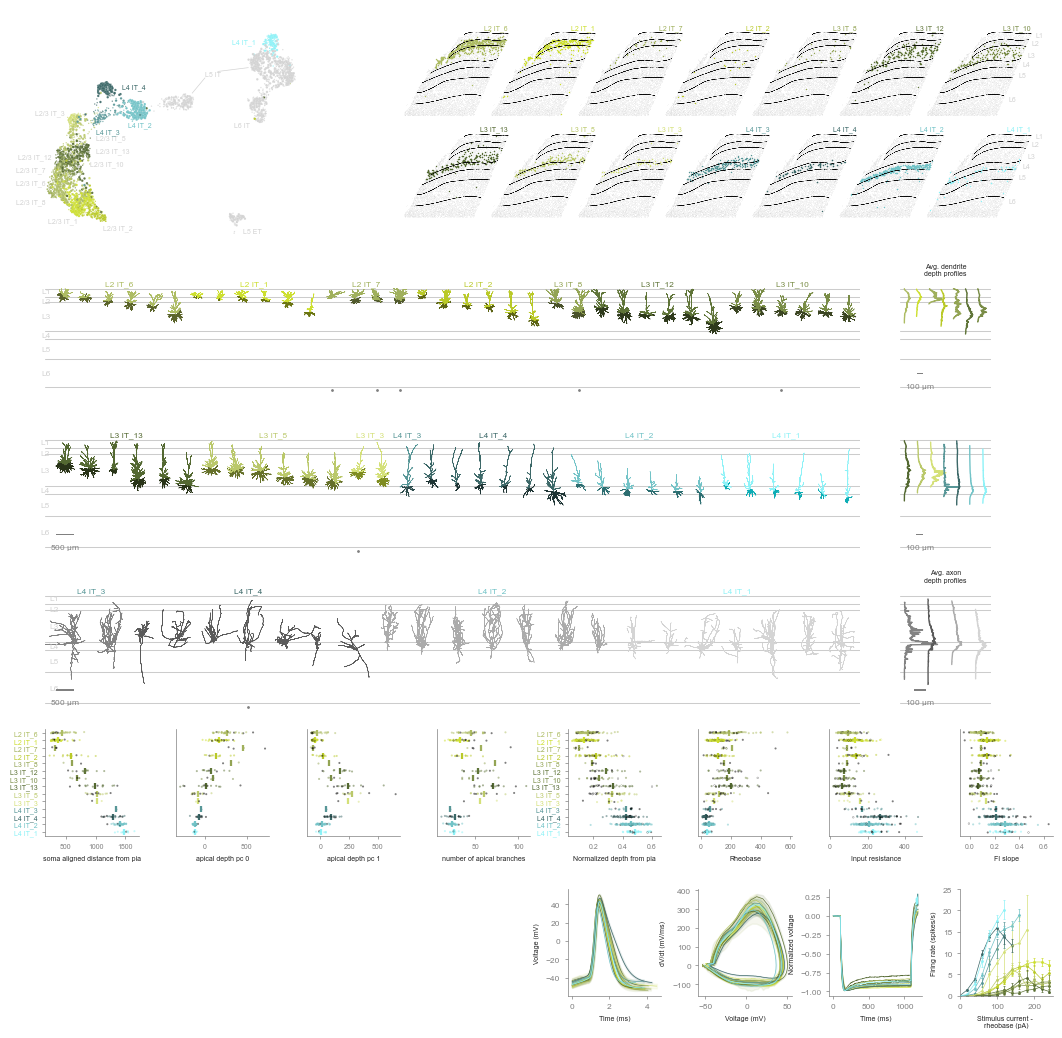

In [38]:
#plot templates
for layer in ['L2/3/4']: #layers:

    subclasses = subclass_order_dict[layer]

    morph_plot_split = group_supertype_split[layer]

    output_file = os.path.join(output_dir, r'{}.pdf'.format(layer.replace(' ', '').replace('/', '-')))
    # if mark_paradigm:
    #     output_file = output_file.replace('.pdf', f'_markParadigm_{mark_paradigm_type}.pdf')

    fig = plt.figure(figsize=group_fig_size[layer])
    gs = gridspec.GridSpec(
        3, 1, height_ratios=group_height_ratios[layer], hspace=0, wspace=0.8)

    ttype_order = flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict])
    morpho_ttype_order = [t for t in ttype_order if t in morpho_sorted_clean_data[morpho_sorted_clean_data['subclass_label'].isin(subclasses)].t_type.unique().tolist()]
    ephys_ttype_order = [t for t in ttype_order if t in ephys_sorted_clean_data[ephys_sorted_clean_data['subclass_label'].isin(subclasses)].t_type.unique().tolist()]

    gs_meta = gridspec.GridSpecFromSubplotSpec(
            1, 2,
            subplot_spec=gs[0],
            width_ratios=meta_ax_width_ratios[layer],
    )

    #UMAP cropping
    reference_umap['color'] = reference_umap.apply(lambda row: color_dict[row['celltype']] if row['subclass'] in subclasses else 'lightgrey', axis=1)
    [(x_min, x_max), (y_min, y_max)] = ref_umap_axes_lims[layer]
    plot_ref_umap_crop(reference_umap, plt.subplot(gs_meta[0]), x_min, x_max, y_min, y_max, SEAAD_COLORS, 
                   supertypes=ttype_order, label_dict=umap_labels[layer], line_list=umap_lines[layer],
                   legend_loc=umap_legend_locs[layer], legend_length=umap_legend_lengths[layer])

    #spatial slice
    plot_spatial_slice(spatial_slice_data, plt.subplot(gs_meta[1]), ttype_order, color_dict, rot_deg=221, ncols=spatial_cols[layer], 
                       skip_subplot=skip_slice_subplot_idxs[layer], overlay_layers=True, overlay_path=spatial_slice_layer_overlay_file)


    # Morphology layer plots
    gs_morph = gridspec.GridSpecFromSubplotSpec(
        3, 2,
        subplot_spec=gs[1],
        width_ratios=(8, 1),
        hspace=0
    )
    #plot two rows of dendrite & one row of L4 axon morphologies

    ax_morph_top = plt.subplot(gs_morph[0, 0])
    plot_morph_lineup_swb(ax_morph_top, morpho_viewer_cells[layer], 't_type', morpho_ttype_order[:morph_plot_split], 
                        layer_aligned_dir, group_layer_edges[layer], group_layer_labels[layer], SEAAD_COLORS, morph_spacing=group_morph_spacing[layer], plot_scalebar=False)

    ax_morph_bottom = plt.subplot(gs_morph[1, 0])
    plot_morph_lineup_swb( ax_morph_bottom, morpho_viewer_cells[layer], 't_type', morpho_ttype_order[morph_plot_split:], 
                        layer_aligned_dir, group_layer_edges[layer], group_layer_labels[layer], SEAAD_COLORS, morph_spacing=group_morph_spacing[layer])

    ax_morph_axon = plt.subplot(gs_morph[2, 0])
    plot_morph_lineup_swb( ax_morph_axon, morpho_viewer_cells_axon[layer], 't_type', morpho_ttype_order, 
                        layer_aligned_dir, group_layer_edges[layer], group_layer_labels[layer], SEAAD_COLORS, morph_spacing=group_morph_spacing[layer]+300, compartment_type = 'axon')

    #plot dendrite depth profiles
    ax_profiles_top = ax_morph_top.inset_axes([1.05, 0, 0.111, 1], transform=ax_morph_top.transAxes)
    ax_morph_top.sharey(ax_profiles_top)
    plot_dendrite_depth_profiles_swb(ax_profiles_top, morpho_sorted_clean_data, 't_type', morpho_ttype_order[:morph_plot_split], aligned_histogram, basal_cols, apical_cols, group_layer_edges[layer], SEAAD_COLORS)
    ax_profiles_top.set_title("Avg. dendrite\ndepth profiles", fontsize=5)

    ax_profiles_bottom = ax_morph_bottom.inset_axes([1.05, 0, 0.111, 1], transform=ax_morph_bottom.transAxes)
    ax_morph_bottom.sharey(ax_profiles_bottom)
    plot_dendrite_depth_profiles_swb(ax_profiles_bottom, morpho_sorted_clean_data, 't_type', morpho_ttype_order[morph_plot_split:], aligned_histogram, basal_cols, apical_cols, group_layer_edges[layer], SEAAD_COLORS)

    ax_profiles_axon = ax_morph_axon.inset_axes([1.05, 0, 0.111, 1], transform=ax_morph_axon.transAxes)
    ax_morph_axon.sharey(ax_profiles_axon)
    plot_axon_depth_profiles_swb(ax_profiles_axon, morpho_data_axon, 't_type', [x for x in morpho_ttype_order if x.startswith('L4')], aligned_histogram_axon, axon_cols, group_layer_edges[layer])
    ax_profiles_axon.set_title("Avg. axon\ndepth profiles", fontsize=5)


    #Morpho & Ephys feature plots
    gs_feat_prop = gridspec.GridSpecFromSubplotSpec(
            2, 8,
            subplot_spec=gs[2],
            width_ratios=(1,1,1,1,1,1,1,1),
            wspace=0.4,
            hspace = 0.5
    )
    #MORPHO

    #get top four eta2 features 
    eta_squared_df = morpho_eta_squared_group[layer]
    eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
    n_features = 4
    top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
    for i, feature in enumerate(top_features):
        plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[0, i]), morpho_ttype_order, morpho_sorted_clean_data, "t_type", feature, feature, 
                               show_yticklabels=(i==0), color_column="t_type_teml", color_dict=color_dict)
        
    #EPHYS

    #get top four eta2 features 
    eta_squared_df = ephys_eta_squared_group[layer]
    eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
    n_features = 4
    top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
    for i, feature in enumerate(top_features):
        plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[0, i+4]), ephys_ttype_order, ephys_sorted_clean_data, "t_type", feature, feature, 
                               show_yticklabels=(i==0), color_column="t_type_teml", color_dict=color_dict, mark_paradigm=mark_paradigm, mark_paradigm_type=mark_paradigm_type)

        
    #EPHYS average trace plots 
    # gs_ephys_trace = gridspec.GridSpecFromSubplotSpec(
    #         1, 8,
    #         subplot_spec=gs[3],
    #         width_ratios=(1,1,1,1,1,1,1,1),
    #         wspace=0.4
    # )
    ephys_cluster_col = 'HANN_cluster_label_assignment_winner'

    #rheobase (ap width)
    plot_ap_ttype(ephys_ap_dict, ephys_ttype_order, ttype_to_subclass_dict, color_dict, plt.subplot(gs_feat_prop[1,4]), 'width')

    #AP phase plot 
    plot_ap_ttype(ephys_ap_dict, ephys_ttype_order, ttype_to_subclass_dict, color_dict, plt.subplot(gs_feat_prop[1,5]), 'phase')

    #subthreshold response
    plot_ephys_subthresh(plt.subplot(gs_feat_prop[1,6]), subthresh_spike_data[layer], subthresh_metadata, ephys_ttype_order, ephys_cluster_col, color_dict)

    #FI curve
    fi_curve_ax = plt.subplot(gs_feat_prop[1,7])
    plot_avg_fi_for_mets(fi_curve_ax, ephys_fi_data_formatted, 't_type', ephys_ttype_order, xlim=fi_xlim[layer], ylim=fi_ylim[layer])

    for ax in fig.get_axes():
        ax.spines['top'].set_linewidth(0.5)
        ax.spines['bottom'].set_linewidth(0.5)
        ax.spines['left'].set_linewidth(0.5)
        ax.spines['right'].set_linewidth(0.5)
        ax.tick_params(axis='both', length=2, width=0.5)

    #save
    plt.savefig(output_file, bbox_inches="tight", dpi=1000)


# Layer 5/6

In [73]:
group_fig_size['L5/6'] = (13, 12)
group_supertype_split['L5/6'] = 12
group_height_ratios['L5/6'] = (2, 3, 2)
meta_ax_width_ratios['L5/6'] = (2, 5)
spatial_cols['L5/6'] = 10
skip_slice_subplot_idxs['L5/6'] = [6]
ref_umap_axes_lims['L5/6'] =  [(-6, 18), (-14, 17)]

umap_labels['L5/6'] = {'L5 IT_6': {'x': 7.5, 'y': 4, 'ha': 'left', 'va': 'center'},
  'L5 IT_5': {'x': 7, 'y': 5.5, 'ha': 'left', 'va': 'center'},
  'L5 IT_2': {'x': 3, 'y': 5, 'ha': 'right', 'va': 'center'},
  'L5 IT_1': {'x': -2, 'y': 3, 'ha': 'right', 'va': 'center'},
  'L5 IT_7': {'x': 4, 'y': 3, 'ha': 'right', 'va': 'center'},
  'L5 IT_3': {'x': -1, 'y': 1, 'ha': 'left', 'va': 'center'},
  'L5/6 NP_2': {'x': 4, 'y': 15, 'ha': 'left', 'va': 'center'},
  'L5/6 NP_6': {'x': 0, 'y': 15, 'ha': 'right', 'va': 'center'},
  'L5/6 NP_1': {'x': 3.5, 'y': 14, 'ha': 'left', 'va': 'center'},
  'L5/6 NP_3': {'x': 0, 'y': 17, 'ha': 'left', 'va': 'center'},
  'L5/6 NP_4': {'x': 0, 'y': 13, 'ha': 'left', 'va': 'center'},
  'L5 ET_1': {'x': 3.5, 'y': -9.5, 'ha': 'left', 'va': 'center'},
  'L5 ET_2': {'x': 4, 'y': -7, 'ha': 'left', 'va': 'center'},
  'L4 IT': {'x': -2, 'y': 7, 'ha': 'left', 'va': 'center'},
  'L6 CT_3': {'x': 14, 'y': 2, 'ha': 'right', 'va': 'center'},
  'L6 CT_2': {'x': 16, 'y': 4, 'ha': 'right', 'va': 'center'},
  'L6 CT_4': {'x': 15.5, 'y': 0.5, 'ha': 'left', 'va': 'center'},
  'L6 CT_1': {'x': 17, 'y': 3, 'ha': 'left', 'va': 'center'},
  'L6 IT_2': {'x': 3, 'y': 2, 'ha': 'right', 'va': 'center'},
  'L6 IT_1': {'x': 5, 'y': -0.5, 'ha': 'right', 'va': 'center'},
  'L6 IT Car3_1': {'x': 0, 'y': -10, 'ha': 'right', 'va': 'center'},
  'L6 IT Car3_3': {'x': -2, 'y': -12, 'ha': 'right', 'va': 'center'},
  'L6 IT Car3_2': {'x': 0.5, 'y': -12.5, 'ha': 'left', 'va': 'center'},
  'L6b_6': {'x': 12.5, 'y': -4, 'ha': 'right', 'va': 'center'},
  'L6b_3': {'x': 14, 'y': -6, 'ha': 'right', 'va': 'center'},
  'L6b_5': {'x': 15, 'y': -3.5, 'ha': 'left', 'va': 'center'},
  'L6b_1': {'x': 17.5, 'y': -6.5, 'ha': 'right', 'va': 'center'},
  'L6b_4': {'x': 17.5, 'y': -4.5, 'ha': 'right', 'va': 'center'},
  'L6b_2': {'x': 15, 'y': -1, 'ha': 'left', 'va': 'center'}}

umap_lines['L5/6'] = [{'x_values': [-2.2, -5.2], 'y_values': [6.5, 2.2]},
                      {'x_values': [-0.2, 4.2], 'y_values': [7, 6.6]},
                      {'x_values': [-0.8, 0.3], 'y_values': [2.4, 3.1]},
                      {'x_values': [1.8, 3.8], 'y_values': [3.3, 3.3]}]

umap_legend_locs['L5/6'] =  [7, -12]
umap_legend_lengths['L5/6'] = 2

# axon_viewer['L5/6'] = False
group_layer_edges['L5/6'] = group_layer_edges['L5']
group_layer_labels['L5/6'] = group_layer_labels['L5']
group_morph_spacing['L5/6'] = 700

subthresh_spike_data['L5/6'] = subthresh_spike_data['L5'] | subthresh_spike_data['L6'] 
fi_xlim['L5/6'] = (0, 250)
fi_ylim['L5/6'] = (0, 25)

c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.

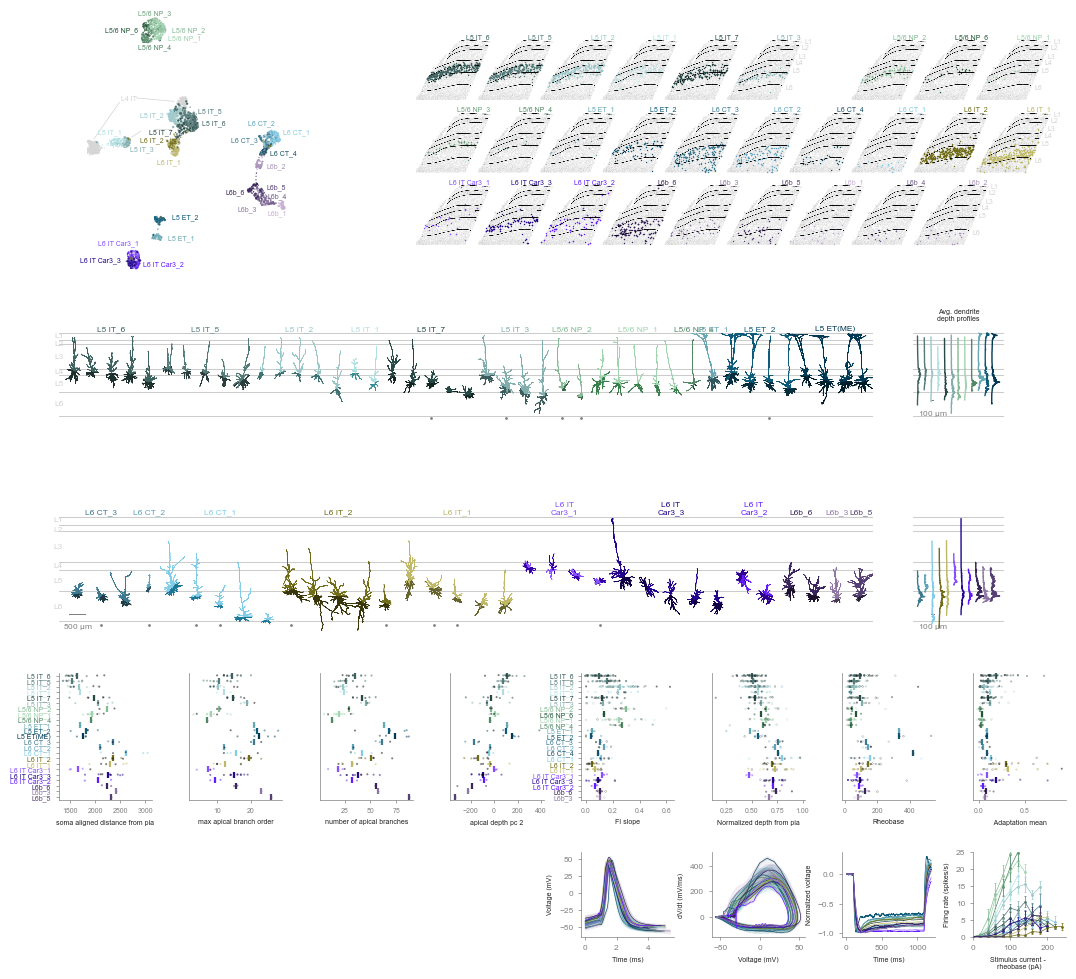

In [74]:
#plot templates
for layer in ['L5/6']: #layers:

    subclasses = subclass_order_dict[layer]

    morph_plot_split = group_supertype_split[layer]

    output_file = os.path.join(output_dir, r'{}.pdf'.format(layer.replace(' ', '').replace('/', '-')))
    # if mark_paradigm:
    #     output_file = output_file.replace('.pdf', f'_markParadigm_{mark_paradigm_type}.pdf')

    fig = plt.figure(figsize=group_fig_size[layer])
    gs = gridspec.GridSpec(
        3, 1, height_ratios=group_height_ratios[layer], hspace=0, wspace=0.8)

    ttype_order = flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict])
    morpho_ttype_order = [t for t in ttype_order if t in morpho_sorted_clean_data[morpho_sorted_clean_data['subclass_label'].isin(subclasses)].t_type.unique().tolist()]
    ephys_ttype_order = [t for t in ttype_order if t in ephys_sorted_clean_data[ephys_sorted_clean_data['subclass_label'].isin(subclasses)].t_type.unique().tolist()]

    gs_meta = gridspec.GridSpecFromSubplotSpec(
            1, 2,
            subplot_spec=gs[0],
            width_ratios=meta_ax_width_ratios[layer],
    )

    #UMAP cropping
    reference_umap['color'] = reference_umap.apply(lambda row: color_dict[row['celltype']] if row['subclass'] in subclasses else 'lightgrey', axis=1)
    [(x_min, x_max), (y_min, y_max)] = ref_umap_axes_lims[layer]
    plot_ref_umap_crop(reference_umap, plt.subplot(gs_meta[0]), x_min, x_max, y_min, y_max, SEAAD_COLORS, 
                   supertypes=ttype_order, label_dict=umap_labels[layer], line_list=umap_lines[layer],
                   legend_loc=umap_legend_locs[layer], legend_length=umap_legend_lengths[layer])

    #spatial slice
    plot_spatial_slice(spatial_slice_data, plt.subplot(gs_meta[1]), ttype_order, color_dict, rot_deg=221, ncols=spatial_cols[layer], 
                       skip_subplot=skip_slice_subplot_idxs[layer], overlay_layers=True, overlay_path=spatial_slice_layer_overlay_file)


    # Morphology layer plots
    gs_morph = gridspec.GridSpecFromSubplotSpec(
        2, 2,
        subplot_spec=gs[1],
        width_ratios=(8, 1),
        hspace=0
    )
    #plot two rows of dendrite & one row of L4 axon morphologies

    ax_morph_top = plt.subplot(gs_morph[0, 0])
    plot_morph_lineup_swb(ax_morph_top, morpho_viewer_cells[layer], 't_type', morpho_ttype_order[:morph_plot_split], 
                        layer_aligned_dir, group_layer_edges[layer], group_layer_labels[layer], SEAAD_COLORS, morph_spacing=group_morph_spacing[layer], plot_scalebar=False)

    ax_morph_bottom = plt.subplot(gs_morph[1, 0])
    plot_morph_lineup_swb( ax_morph_bottom, morpho_viewer_cells[layer], 't_type', morpho_ttype_order[morph_plot_split:], 
                        layer_aligned_dir, group_layer_edges[layer], group_layer_labels[layer], SEAAD_COLORS, morph_spacing=group_morph_spacing[layer])

    #plot dendrite depth profiles
    ax_profiles_top = ax_morph_top.inset_axes([1.05, 0, 0.111, 1], transform=ax_morph_top.transAxes)
    ax_morph_top.sharey(ax_profiles_top)
    plot_dendrite_depth_profiles_swb(ax_profiles_top, morpho_sorted_clean_data, 't_type', morpho_ttype_order[:morph_plot_split], aligned_histogram, basal_cols, apical_cols, group_layer_edges[layer], SEAAD_COLORS)
    ax_profiles_top.set_title("Avg. dendrite\ndepth profiles", fontsize=5)

    ax_profiles_bottom = ax_morph_bottom.inset_axes([1.05, 0, 0.111, 1], transform=ax_morph_bottom.transAxes)
    ax_morph_bottom.sharey(ax_profiles_bottom)
    plot_dendrite_depth_profiles_swb(ax_profiles_bottom, morpho_sorted_clean_data, 't_type', morpho_ttype_order[morph_plot_split:], aligned_histogram, basal_cols, apical_cols, group_layer_edges[layer], SEAAD_COLORS)


    #Morpho & Ephys feature plots
    gs_feat_prop = gridspec.GridSpecFromSubplotSpec(
            2, 8,
            subplot_spec=gs[2],
            width_ratios=(1,1,1,1,1,1,1,1),
            height_ratios=(1.5,1),
            wspace=0.4,
            hspace = 0.5
    )
    #MORPHO

    #get top four eta2 features 
    eta_squared_df = morpho_eta_squared_group[layer]
    eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
    n_features = 4
    top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
    for i, feature in enumerate(top_features):
        plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[0, i]), morpho_ttype_order, morpho_sorted_clean_data, "t_type", feature, feature, 
                               show_yticklabels=(i==0), color_column="t_type_teml", color_dict=color_dict)
        
    #EPHYS

    #get top four eta2 features 
    eta_squared_df = ephys_eta_squared_group[layer]
    eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
    n_features = 4
    top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
    for i, feature in enumerate(top_features):
        plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[0, i+4]), ephys_ttype_order, ephys_sorted_clean_data, "t_type", feature, feature, 
                               show_yticklabels=(i==0), color_column="t_type_teml", color_dict=color_dict, mark_paradigm=mark_paradigm, mark_paradigm_type=mark_paradigm_type)

        
    #EPHYS average trace plots 
    ephys_cluster_col = 'HANN_cluster_label_assignment_winner'

    #rheobase (ap width)
    plot_ap_ttype(ephys_ap_dict, ephys_ttype_order, ttype_to_subclass_dict, color_dict, plt.subplot(gs_feat_prop[1,4]), 'width')

    #AP phase plot 
    plot_ap_ttype(ephys_ap_dict, ephys_ttype_order, ttype_to_subclass_dict, color_dict, plt.subplot(gs_feat_prop[1,5]), 'phase')

    #subthreshold response
    plot_ephys_subthresh(plt.subplot(gs_feat_prop[1,6]), subthresh_spike_data[layer], subthresh_metadata, ephys_ttype_order, ephys_cluster_col, color_dict)

    #FI curve
    fi_curve_ax = plt.subplot(gs_feat_prop[1,7])
    plot_avg_fi_for_mets(fi_curve_ax, ephys_fi_data_formatted, 't_type', ephys_ttype_order, xlim=fi_xlim[layer], ylim=fi_ylim[layer])

    for ax in fig.get_axes():
        ax.spines['top'].set_linewidth(0.5)
        ax.spines['bottom'].set_linewidth(0.5)
        ax.spines['left'].set_linewidth(0.5)
        ax.spines['right'].set_linewidth(0.5)
        ax.tick_params(axis='both', length=2, width=0.5)

    #save
    plt.savefig(output_file, bbox_inches="tight", dpi=1000)


# Subclass Templates

### Analysis 

Morpho Eta2 and FDR corrected KW of ttypes within each subclass

In [11]:
features = raw_feature_wide.columns.tolist()[1:]

group_data = morpho_sorted_clean_data 

# Get subclasses
x_var = 'subclass_label'
x_var_order =  list(tx_order_dict.keys())

# Initialize dictionaries for Kruskal-Wallis H test and p-values
kw_hvals = dict()
kw_pvals = dict()

# Iterate over features to calculate KW test and eta-squared
for f in features:
    # Get groups of data for each subclass
    s_groups = [group_data.loc[group_data[x_var] == x][f].dropna() for x in x_var_order]

    # Only include non-empty groups with at least 1 cell
    s_groups = [g for g in s_groups if len(g) >= 1]

    if len(s_groups) < 2:
        print(f"Not enough s_groups with data for feature {f}")
        continue

    try:
        hvalue, pvalue = stats.kruskal(*s_groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction for KW p-values
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), kw_pvals_fdr_list))
kw_rejected = dict(zip(list(kw_pvals.keys()), kw_rejected_list))

# Post-hoc Dunn test for significant KW features (after FDR correction)
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # only if null hypothesis was rejected
        dunn_pvals_fdr[k] = posthoc_dunn(group_data[group_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

# Calculate eta-squared for the KW H-test
eta_squared_subclasses = {}
k = len(s_groups)  # number of t-types (groups)
n = sum([len(g) for g in s_groups])  # total number of observations
print(f'k: {k}, n: {n}')
for f, h in kw_hvals.items():
    esq = (h - k + 1) / (n - k)  # eta^2 formula for KW test
    eta_squared_subclasses[f] = esq

eta_squared_subclasses_df = pd.DataFrame.from_dict(sorted(eta_squared_subclasses.items(), key=operator.itemgetter(1), reverse=True))
eta_squared_subclasses_df.rename(columns={0: 'feature', 1: 'eta_squared'}, inplace=True)

# Store results
morpho_eta_squared_subclass = eta_squared_subclasses_df
morpho_kw_pvals_fdr_subclass = kw_pvals_fdr
morpho_dunn_pvals_fdr_subclass = dunn_pvals_fdr


k: 9, n: 319


Ephys Eta2 and FDR corrected KW of ttypes within each subclass

In [12]:
#Exclude the two features where < 25% of cells have a value
exclude_features = ['Chirp peak','ZAP (peak impedance)']
features = [f for f in ephys_feature_cols if f not in exclude_features]

group_data = ephys_sorted_clean_data 

# Get subclasses
x_var = 'subclass_label'
x_var_order =  list(tx_order_dict.keys())

# Initialize dictionaries for Kruskal-Wallis H test and p-values
kw_hvals = dict()
kw_pvals = dict()

# Iterate over features to calculate KW test and eta-squared
for f in features:
    # Get groups of data for each subclass
    s_groups = [group_data.loc[group_data[x_var] == x][f].dropna() for x in x_var_order]

    if acute_only:
        s_groups = s_groups[s_groups.paradigm == 'acute']

    # Only include non-empty groups with at least 1 cell
    s_groups = [g for g in s_groups if len(g) >= 1]

    if len(s_groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue

    try:
        hvalue, pvalue = stats.kruskal(*s_groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction for KW p-values
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), kw_pvals_fdr_list))
kw_rejected = dict(zip(list(kw_pvals.keys()), kw_rejected_list))

# Post-hoc Dunn test for significant KW features (after FDR correction)
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # only if null hypothesis was rejected
        dunn_pvals_fdr[k] = posthoc_dunn(group_data[group_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

# Calculate eta-squared for the KW H-test
eta_squared_subclasses = {}
k = len(s_groups)  # number of t-types (t_groups)
n = sum([len(g) for g in s_groups])  # total number of observations
print(f'k: {k}, n: {n}')
for f, h in kw_hvals.items():
    esq = (h - k + 1) / (n - k)  # eta^2 formula for KW test
    eta_squared_subclasses[f] = esq

eta_squared_subclasses_df = pd.DataFrame.from_dict(sorted(eta_squared_subclasses.items(), key=operator.itemgetter(1), reverse=True))
eta_squared_subclasses_df.rename(columns={0: 'feature', 1: 'eta_squared'}, inplace=True)

# Store results
ephys_eta_squared_subclass = eta_squared_subclasses_df
ephys_kw_pvals_fdr_subclass = kw_pvals_fdr
ephys_dunn_pvals_fdr_subclass = dunn_pvals_fdr


Kruskal-Wallis not calculated for ephys because of an error: All numbers are identical in kruskal
k: 9, n: 959


Process apical distal tips 

In [ ]:
# subclass_apical_dict = process_distal_apicals(morpho_sorted_clean_data, SUBCLASS_ORDER, 'subclass_label')

Formatting specs

In [14]:
subclass_xoffsets = {
    'L2/3 IT': 1000,
    'L4 IT': 3000,
    'L5 IT': 5000,
    'L5/6 NP': 7000,
    'L5 ET': 9000,
    'L6 IT Car3': 11300,
    'L6 IT': 13500,
    'L6 CT': 15800,
    'L6b': 17800
}

heatmap_mask_dict = {
    'L4 IT' : 2000,
    'L5 IT' : 4000,
    'L5/6 NP' : 6000,
    'L5 ET' : 8000,
    'L6 IT Car3': 10000,
    'L6 IT': 12000,
    'L6 CT': 14000,
    'L6b': 16000
}

histo_xoffsets = {
    'L2/3 IT': 2100, 
    'L4 IT' : 4300,
    'L5 IT' : 7000,
    'L5/6 NP' : 9200,
    'L5 ET' : 11300,
    'L6 IT Car3': 13900,
    'L6 IT': 15300,
    'L6 CT': 17700,
    'L6b': 20000
}

heatmap_xlim = (0, 18500) #289
heatmap_ylim = (-3380, 0)

apical_buffer_dict = {
    'L2/3 IT' : 50, 
    'L4 IT' : 50,     
    'L5 IT' : 50, 
    'L5/6 NP' : 50, 
    'L5 ET' : 70, 
    'L6 IT Car3' : 70, 
    'L6 IT' : 70, 
    'L6 CT' : 70, 
    'L6b' : 100, 
}

In [15]:
# Define custom colormap
colors_d = [
    (1.0, 1.0, 1.0),   # white
    (0.88, 0.92, 0.97),# very pale blue (almost white with a cool tint)
    (0.45, 0.60, 0.85),# medium muted blue
    (0.10, 0.20, 0.40) # dark indigo/blue
]

colors_a = [
    (1.0, 1.0, 1.0),   # white
    (1.0, 0.9, 0.8),   # very light orange
    (1.0, 0.6, 0.2),   # medium orange
    (0.5, 0.15, 0.0)   # dark orange / brownish
]

# Positions (stretches the light part)
positions = [0.0, 0.1, 0.5, 1.0]

custom_cmap_d = mcolors.LinearSegmentedColormap.from_list("custom_dend_dark", list(zip(positions, colors_d)))
custom_cmap_a = mcolors.LinearSegmentedColormap.from_list("custom_axon_dark", list(zip(positions, colors_a)))

### Plot

Subclass - Fig1

In [94]:
subclass_xoffsets = {'L2/3 IT': 1000-300, 
                     'L4 IT': 3000-600, 
                     'L5 IT': 5000-900, 
                     'L5/6 NP': 7000-1200, 
                     'L5 ET': 9000-1400, 
                     'L6 IT Car3': 11300-1500, 
                     'L6 IT': 13500-1500, 
                     'L6 CT': 15800-1600, 
                     'L6b': 17800-1700} 


heatmap_mask_dict = {'L4 IT': 2000-600, 
                     'L5 IT': 4000-900, 
                     'L5/6 NP': 6000-1200, 
                     'L5 ET': 8000-1400, 
                     'L6 IT Car3': 10000-1500, 
                     'L6 IT': 12000-1500, 
                     'L6 CT': 14000-1600, 
                     'L6b': 16000-1700}

heatmap_xlim = (0, 18500-1800)

ephys_umap_labels = {'L2/3 IT' : {'x':10, 'y':-0.5, 'ha': 'center', 'va':'center'},
                     'L4 IT' : {'x':0.2 , 'y':4 , 'ha': 'right', 'va': 'center'},
                     'L5 IT' : {'x': 1, 'y':5.5 , 'ha': 'right', 'va': 'center'},
                     'L5/6 NP' : {'x': 6.5, 'y':7 , 'ha': 'left', 'va': 'center'},
                     'L5 ET' : {'x': 7.8, 'y':-2, 'ha': 'left', 'va': 'center'},
                     'L6 IT Car3' : {'x':12, 'y':4, 'ha': 'left', 'va': 'center'},
                     'L6 IT' : {'x': 11.5, 'y': 5.1, 'ha': 'left', 'va': 'center'},
                     'L6 CT' : {'x': 11, 'y': 6.5, 'ha': 'left', 'va': 'center'},
                     'L6b' : {'x': 7.5, 'y': 7, 'ha': 'right', 'va': 'center'}}

morpho_umap_labels = {'L2/3 IT' : {'x':0, 'y':6.5, 'ha': 'center', 'va':'center'},
                     'L4 IT' : {'x':3 , 'y':-1 , 'ha': 'right', 'va': 'center'},
                     'L5 IT' : {'x': 6.5, 'y':1 , 'ha': 'left', 'va': 'center'}, 
                     'L5/6 NP' : {'x': 6, 'y':0 , 'ha': 'left', 'va': 'center'}, 
                     'L5 ET' : {'x': 6, 'y':4.3, 'ha': 'left', 'va': 'center'},
                     'L6 IT Car3' : {'x':2, 'y':2.5, 'ha': 'right', 'va': 'center'}, 
                     'L6 IT' : {'x': 7, 'y': 3, 'ha': 'left', 'va': 'center'}, 
                     'L6 CT' : {'x': 6.5, 'y': 2, 'ha': 'left', 'va': 'center'}, 
                     'L6b' : {'x': 6.5, 'y': 3.5, 'ha': 'left', 'va': 'center'}}

me_umap_labels = {'L2/3 IT': {'y': 6.5, 'x': 7, 'ha': 'center', 'va': 'center'},
                  'L4 IT': {'y': -0.8, 'x': 9, 'ha': 'right', 'va': 'center'},
                  'L5 IT': {'y': 1, 'x': 5.5, 'ha': 'left', 'va': 'center'},
                  'L5/6 NP': {'y': -1.5, 'x': 7, 'ha': 'right', 'va': 'center'},
                  'L5 ET': {'y': 3.2, 'x': 5, 'ha': 'left', 'va': 'center'},
                  'L6 IT Car3': {'y': 3, 'x': 8.4, 'ha': 'right', 'va': 'center'},
                  'L6 IT': {'y': 2, 'x': 5, 'ha': 'left', 'va': 'center'},
                  'L6 CT': {'y': 5.8, 'x': 6, 'ha': 'left', 'va': 'center'},
                  'L6b': {'y': 0, 'x': 6, 'ha': 'left', 'va': 'center'}}

heatmap_dendrite_cells = {
    'L2/3 IT' : 1084380898,
    'L4 IT' : 758312441,
    'L5 IT' : 1230988535,
    'L5/6 NP' : 1163016273,
    'L5 ET' : 1402898753,
    'L6 IT Car3' : 1161609703,
    'L6 IT' : 757173647,
    'L6 CT' : 1221146385,
    'L6b' : 592479953}

heatmap_axon_cells = {
    'L2/3 IT' : 689309060,
    'L4 IT' : 868182038,
    'L5 IT' : 695500665,
    'L5/6 NP' : 1164349747,
    'L5 ET' : 1161768653,
    'L6 IT Car3' : 1187969093,
    'L6 IT' : 793528028,
    'L6 CT' : 1310107671,
    'L6b' : 1161645348}

overlay_morphology = False #overlay morphos on the subclass heatmaps?
plot_hairball = True

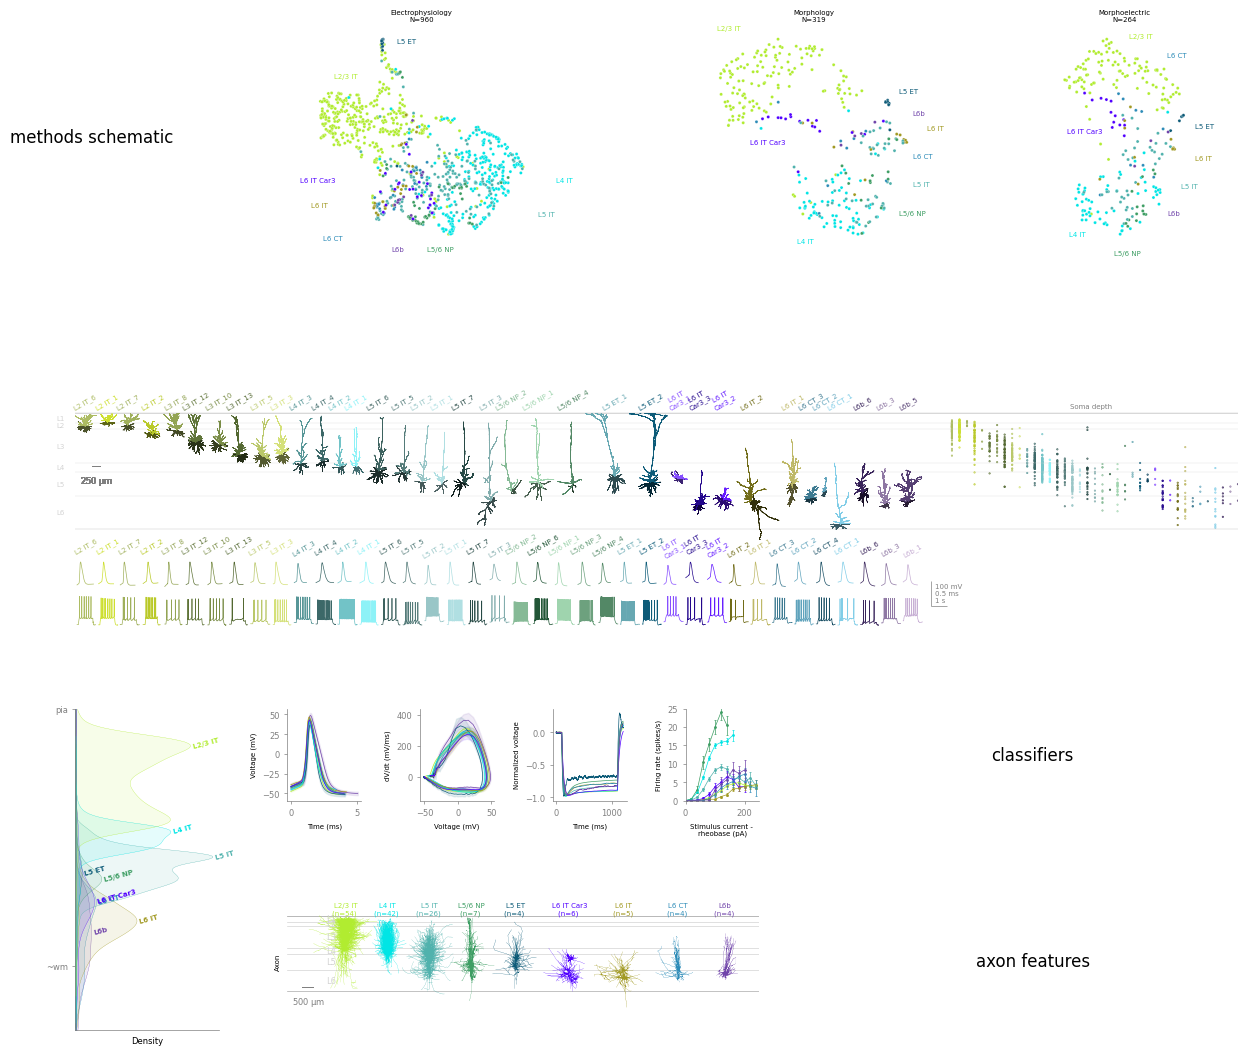

In [156]:
# plot templates
output_file = os.path.join(output_dir, f'subclass.pdf')

subclasses = list(tx_order_dict.keys())
morpho_subclass_order = [s for s in subclasses if s in morpho_sorted_clean_data['subclass_label'].unique()]
ephys_subclass_order = [s for s in subclasses if s in ephys_sorted_clean_data['subclass_label'].unique()]

fig = plt.figure(figsize=group_fig_size['subclass'])
gs = gridspec.GridSpec(3, 1, 
                       height_ratios=(2, 2, 3),
                       hspace=0.5)
#################
# Method & UMAPs
#################
gs_row1 = gridspec.GridSpecFromSubplotSpec(1, 6,
                                           width_ratios=(0.1, 0.1, 0.1, 1.2, 1.1, 0.7),
                                           wspace=0.1,
                                           subplot_spec=gs[0])

#space to put methods schematic
ax_method = plt.subplot(gs_row1[0])
ax_method.axis('off')
ax_method.text(
    0.5, 0.5,
    'methods schematic',
    ha='center',
    va='center',
    fontsize=12
)

#patchseq UMAPs
ax_umap_e = plt.subplot(gs_row1[3])
plot_umap(ax_umap_e, e_umap, subclass_col, subclasses, color_dict, umap1_label='e-UMAP2', umap2_label='e-UMAP1', label_dict=ephys_umap_labels) #swap label order to flip both axes for better umap visual alignment across modalities 
ax_umap_e.set_title('Electrophysiology\nN={}'.format(len(e_umap)), size=5)
ax_umap_e.invert_xaxis()
ax_umap_e.invert_yaxis()

ax_umap_m = plt.subplot(gs_row1[4])
plot_umap(ax_umap_m, m_umap, subclass_col, subclasses, color_dict, umap1_label='m-UMAP1', umap2_label='m-UMAP2', label_dict=morpho_umap_labels)
ax_umap_m.set_title('Morphology\nN={}'.format(len(m_umap)), size=5)

ax_umap_me = plt.subplot(gs_row1[5])
plot_umap(ax_umap_me, me_umap, subclass_col, subclasses, color_dict, x_col='umap_2', y_col='umap_1', umap1_label='me-UMAP2', umap2_label='me-UMAP1', label_dict=me_umap_labels)
ax_umap_me.set_title('Morphoelectric\nN={}'.format(len(me_umap)), size=5)
ax_umap_me.invert_xaxis()



##########################
# ME gallery + soma depths
##########################
gs_row2 = gridspec.GridSpecFromSubplotSpec(1, 1,
                                           subplot_spec=gs[1])
ax_gallery = plt.subplot(gs_row2[0])
morpho_end_xoffset = plot_morpho_gallery(ax_gallery, gallery_cells, morpho_sorted_clean_data, soma_depths, layer_info, layer_labels, color_dict, TTYPE_ORDER, plot_scalebar=True, plot_somadepth=True)



###################
# Subclass analysis
###################
gs_row3 = gridspec.GridSpecFromSubplotSpec(2, 3,
                                           width_ratios=(0.7,2.3,2),
                                           height_ratios=(1,1.5),
                                           subplot_spec=gs[2],
                                           hspace=0.8)

#MERFISH spatial density 
plot_spatial_density_kde(isodepth_df, plt.subplot(gs_row3[:,0]), 'scaled_gaston_isodepth', 'SEAAD_Subclass_name', 
                         [s for s in subclasses if s in isodepth_df.SEAAD_Subclass_name.unique()], color_dict, label_peaks=True)


#EPHYS average trace plots 
gs_ephys_trace = gridspec.GridSpecFromSubplotSpec(
        1, 4,
        subplot_spec=gs_row3[0, 1],
        width_ratios=(1,1,1,1),
        wspace=0.8
)
ephys_subclass_col = 'HANN_subclass_label_assignment_winner' #TODO is this still correct?

# #rheobase (ap width)
plot_ap_subclass(ephys_ap_dict, color_dict, plt.subplot(gs_ephys_trace[0]), 'width')

#AP phase plot 
plot_ap_subclass(ephys_ap_dict, color_dict, plt.subplot(gs_ephys_trace[1]), 'phase')

#subthreshold response
subthresh_spike_data = np.load(os.path.join(ephys_subthresh_dir, 'subthreshold_data_subclass.npy'), allow_pickle=True)[()]
subthresh_metadata = pd.read_csv(os.path.join(ephys_subthresh_dir, 'subthreshold_metadata.csv'))
plot_ephys_subthresh(plt.subplot(gs_ephys_trace[2]), subthresh_spike_data, subthresh_metadata, list(tx_order_dict.keys()), ephys_subclass_col, color_dict)

#FI curve
plot_avg_fi_for_mets(plt.subplot(gs_ephys_trace[3]), ephys_fi_data_formatted, 'subclass_label', list(tx_order_dict.keys()))


#Axon morphologies 
ax_axon_hairballs = plt.subplot(gs_row3[1, 1])
if plot_hairball:
    plot_subclass_hairballs(ax_axon_hairballs, morpho_sorted_clean_data[morpho_sorted_clean_data.has_axon], SUBCLASS_ORDER, layer_info, layer_colors, layer_labels, color_dict, subclass_xoffsets, compartment_list=[1,2], plot_scalebar=True, ylabel='Axon')


#space to put classifiers
ax_classifiers = plt.subplot(gs_row3[0,2])
ax_classifiers.axis('off')
ax_classifiers.text(0.5, 0.5, 'classifiers', ha='center', va='center', fontsize=12)

#space to put top axon scatters
ax_axon_feats = plt.subplot(gs_row3[1,2])
ax_axon_feats.axis('off')
ax_axon_feats.text(0.5, 0.5, 'axon features', ha='center', va='center', fontsize=12)

#plot the ephys gallery (it corrupts the fig, so plot it last)
plot_ephys_gallery(fig, ax_gallery, svg_root, flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict]), color_dict, end_xoffset=0.58, plot_scalebar=True)
# plot_ephys_gallery(fig, ax_gallery, svg_root, flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict]), color_dict, plot_scalebar=True)

for ax in fig.get_axes():
    ax.spines['top'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['right'].set_linewidth(0.5)
    ax.tick_params(axis='both', length=2, width=0.5)

plt.savefig(output_file, bbox_inches="tight", dpi=500)


# ARCHIVE 

Subclass part 1

\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\templates\template_utils_v5.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='lobe', data=df, order=order, ax=ax, palette=color_dict)
\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\templates\template_utils_v5.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')  #Rotate x labels


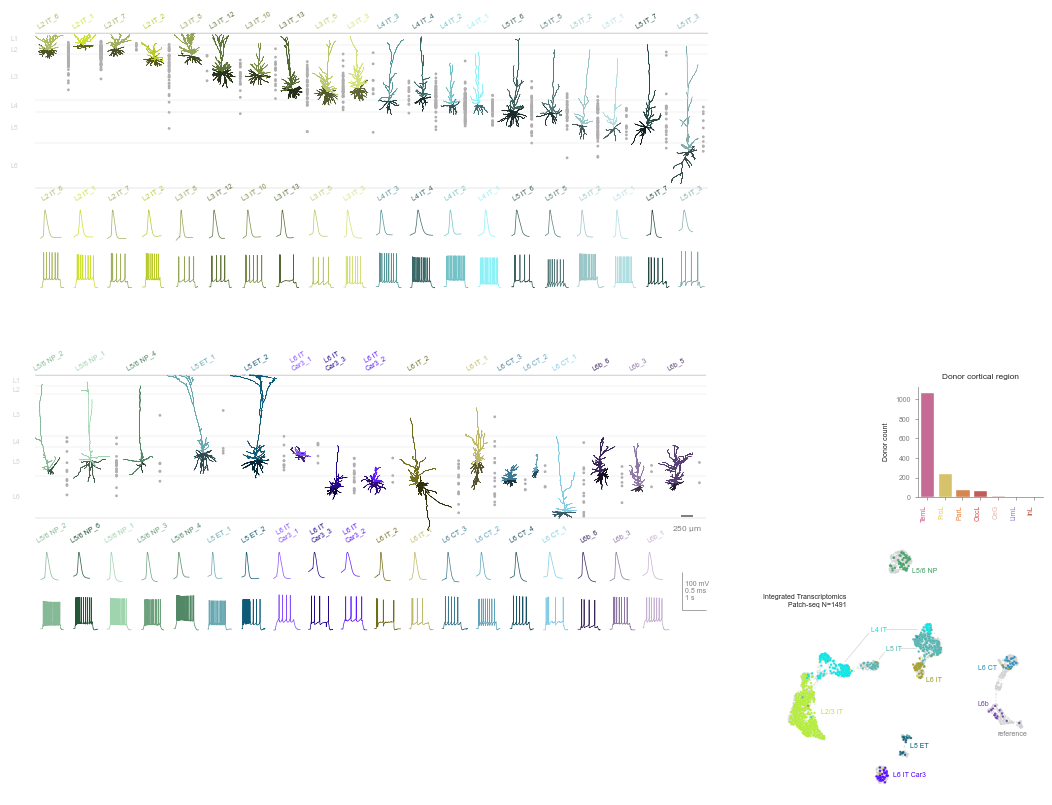

In [29]:
# plot templates
output_file = os.path.join(output_dir, f'subclass_1.pdf')

subclasses = list(tx_order_dict.keys())
morpho_subclass_order = [s for s in subclasses if s in morpho_sorted_clean_data['subclass_label'].unique()]
ephys_subclass_order = [s for s in subclasses if s in ephys_sorted_clean_data['subclass_label'].unique()]

fig = plt.figure(figsize=group_fig_size['subclass_1'])
gs = gridspec.GridSpec(2, 2, 
                       width_ratios=(8,3), 
                       height_ratios=(6,3),
                       wspace=0, 
                       hspace=0)

# ME gallery 
gs_gallery = gridspec.GridSpecFromSubplotSpec(
    2, 1, 
    subplot_spec=gs[0],
    hspace=1
)
ax_gallery_top = plt.subplot(gs_gallery[0])
plot_morpho_gallery(ax_gallery_top, gallery_cells[:20], morpho_sorted_clean_data, soma_depths, layer_info, layer_labels, color_dict, plot_scalebar=False)

ax_gallery_bottom = plt.subplot(gs_gallery[1])
plot_morpho_gallery(ax_gallery_bottom, gallery_cells[20:], morpho_sorted_clean_data, soma_depths, layer_info, layer_labels, color_dict, buffer=150)

# (ephys gallery plotted at the end)

# Col 2
gs_col2 = gridspec.GridSpecFromSubplotSpec(
    3, 2, 
    subplot_spec=gs[1],
    width_ratios=(1,1),
    height_ratios=(3,1,0.1))

#donor lobe count
ax_donor_region = plt.subplot(gs_col2[1,1])
plot_donor_lobe_counts(ax_donor_region, metadata, lobe_colors)

# Row 2
gs_row2 = gridspec.GridSpecFromSubplotSpec(
    1, 1, 
    subplot_spec=gs[1, 1])

#reference UMAP
ax_umap_ref = plt.subplot(gs_row2[0])
reference_umap['color'] = reference_umap.apply(lambda row: color_dict[row['subclass']] if row['subclass'] in subclasses else 'lightgrey', axis=1)
plot_ref_umap(reference_umap, ax_umap_ref, label_dict=umap_labels['subclass'], line_list=umap_lines['subclass'])
ax_umap_ref.text(-5, 10, 'Integrated Transcriptomics\nPatch-seq N={}'.format(reference_umap.platform.value_counts()['patch-seq']), fontsize=5, ha='right', va='center')

#plot the ephys gallery (it corrupts the fig, so plot it last)
plot_ephys_gallery(fig, ax_gallery_top, svg_root, flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict])[:20], color_dict, plot_scalebar=False)
plot_ephys_gallery(fig, ax_gallery_bottom, svg_root, flatten([tx_order_dict[sub] for sub in subclasses if sub in tx_order_dict])[20:], color_dict)

for ax in fig.get_axes():
    ax.spines['top'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['right'].set_linewidth(0.5)
    ax.tick_params(axis='both', length=2, width=0.5)

plt.savefig(output_file, bbox_inches="tight", dpi=600)


Subclass part 2

In [30]:
subclass_xoffsets = {'L2/3 IT': 1000-300, 
                     'L4 IT': 3000-600, 
                     'L5 IT': 5000-900, 
                     'L5/6 NP': 7000-1200, 
                     'L5 ET': 9000-1400, 
                     'L6 IT Car3': 11300-1500, 
                     'L6 IT': 13500-1500, 
                     'L6 CT': 15800-1600, 
                     'L6b': 17800-1700} 


heatmap_mask_dict = {'L4 IT': 2000-600, 
                     'L5 IT': 4000-900, 
                     'L5/6 NP': 6000-1200, 
                     'L5 ET': 8000-1400, 
                     'L6 IT Car3': 10000-1500, 
                     'L6 IT': 12000-1500, 
                     'L6 CT': 14000-1600, 
                     'L6b': 16000-1700}

heatmap_xlim = (0, 18500-1800)

ephys_umap_labels = {'L2/3 IT' : {'x':10, 'y':-0.5, 'ha': 'center', 'va':'center'},
                     'L4 IT' : {'x':0.2 , 'y':4 , 'ha': 'right', 'va': 'center'},
                     'L5 IT' : {'x': 1, 'y':5.5 , 'ha': 'right', 'va': 'center'},
                     'L5/6 NP' : {'x': 6.5, 'y':7 , 'ha': 'left', 'va': 'center'},
                     'L5 ET' : {'x': 7.8, 'y':-2, 'ha': 'left', 'va': 'center'},
                     'L6 IT Car3' : {'x':12, 'y':4, 'ha': 'left', 'va': 'center'},
                     'L6 IT' : {'x': 11.5, 'y': 5.1, 'ha': 'left', 'va': 'center'},
                     'L6 CT' : {'x': 11, 'y': 6.5, 'ha': 'left', 'va': 'center'},
                     'L6b' : {'x': 7.5, 'y': 7, 'ha': 'right', 'va': 'center'}}

morpho_umap_labels = {'L2/3 IT' : {'x':0, 'y':6.5, 'ha': 'center', 'va':'center'},
                     'L4 IT' : {'x':3 , 'y':-1 , 'ha': 'right', 'va': 'center'},
                     'L5 IT' : {'x': 6.5, 'y':1 , 'ha': 'left', 'va': 'center'}, 
                     'L5/6 NP' : {'x': 6, 'y':0 , 'ha': 'left', 'va': 'center'}, 
                     'L5 ET' : {'x': 6, 'y':4.3, 'ha': 'left', 'va': 'center'},
                     'L6 IT Car3' : {'x':2, 'y':2.5, 'ha': 'right', 'va': 'center'}, 
                     'L6 IT' : {'x': 7, 'y': 3, 'ha': 'left', 'va': 'center'}, 
                     'L6 CT' : {'x': 6.5, 'y': 2, 'ha': 'left', 'va': 'center'}, 
                     'L6b' : {'x': 6.5, 'y': 3.5, 'ha': 'left', 'va': 'center'}}

me_umap_labels = {'L2/3 IT': {'y': 6.5, 'x': 7, 'ha': 'center', 'va': 'center'},
                  'L4 IT': {'y': -0.8, 'x': 9, 'ha': 'right', 'va': 'center'},
                  'L5 IT': {'y': 1, 'x': 5.5, 'ha': 'left', 'va': 'center'},
                  'L5/6 NP': {'y': -1.5, 'x': 7, 'ha': 'right', 'va': 'center'},
                  'L5 ET': {'y': 3.2, 'x': 5, 'ha': 'left', 'va': 'center'},
                  'L6 IT Car3': {'y': 3, 'x': 8.4, 'ha': 'right', 'va': 'center'},
                  'L6 IT': {'y': 2, 'x': 5, 'ha': 'left', 'va': 'center'},
                  'L6 CT': {'y': 5.8, 'x': 6, 'ha': 'left', 'va': 'center'},
                  'L6b': {'y': 0, 'x': 6, 'ha': 'left', 'va': 'center'}}

heatmap_dendrite_cells = {
    'L2/3 IT' : 1084380898,
    'L4 IT' : 758312441,
    'L5 IT' : 1230988535,
    'L5/6 NP' : 1163016273,
    'L5 ET' : 1402898753,
    'L6 IT Car3' : 1161609703,
    'L6 IT' : 757173647,
    'L6 CT' : 1221146385,
    'L6b' : 592479953}

heatmap_axon_cells = {
    'L2/3 IT' : 689309060,
    'L4 IT' : 868182038,
    'L5 IT' : 695500665,
    'L5/6 NP' : 1164349747,
    'L5 ET' : 1161768653,
    'L6 IT Car3' : 1187969093,
    'L6 IT' : 793528028,
    'L6 CT' : 1310107671,
    'L6b' : 1161645348}

overlay_morphology = False #overlay morphos on the subclass heatmaps?
plot_hairball = True

\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\templates\template_utils.py:503: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="eta_squared", y='feature', data=eta_squared_ttypes_df, palette=color_palette)
\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\code\templates\template_utils.py:521: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), ha=label_ha, fontsize=6)  # Align labels to the left/right
c:\Users\sarah.wallingbell\AppData\Local\anaconda3\envs\morph_utils_v5\lib\site-packages\matplotlib_scalebar\scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotatio

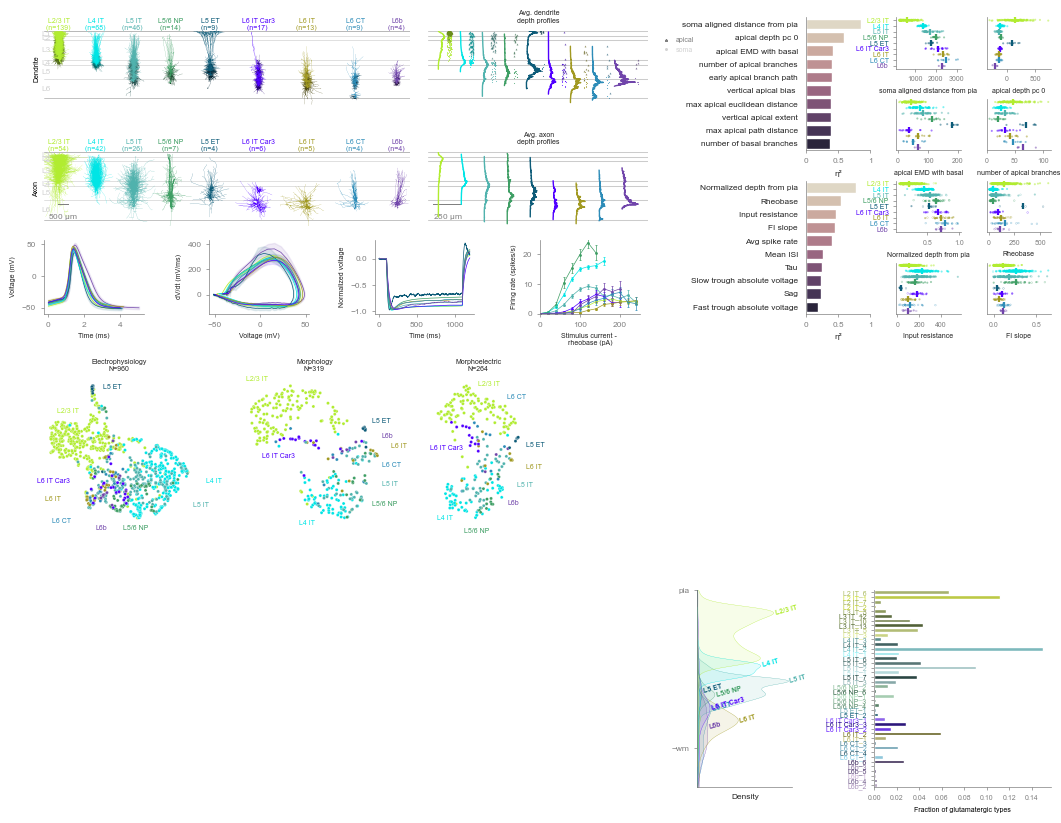

In [31]:
# plot templates
output_file = os.path.join(output_dir, f'subclass_2.pdf')
# if plot_hairball:
#     output_file = output_file.replace('.pdf', '_hairball.pdf')
# if mark_paradigm:
#     output_file = output_file.replace('.pdf', f'_markParadigm_{mark_paradigm_type}.pdf')

subclasses = list(tx_order_dict.keys())
morpho_subclass_order = [s for s in subclasses if s in morpho_sorted_clean_data['subclass_label'].unique()]
ephys_subclass_order = [s for s in subclasses if s in ephys_sorted_clean_data['subclass_label'].unique()]

fig = plt.figure(figsize=group_fig_size['subclass_2'])
gs = gridspec.GridSpec(3, 1, height_ratios=(6, 3, 4), hspace=0.3, wspace=0.1)

gs_row1 = gridspec.GridSpecFromSubplotSpec(
    2, 2,
    subplot_spec=gs[0],
    width_ratios=(2,1),
    height_ratios=(3,1),
    wspace=0,
    hspace=0
)

gs_morph = gridspec.GridSpecFromSubplotSpec(
    2, 2,
    subplot_spec=gs_row1[0,0],
    width_ratios=(3,2),
    height_ratios=(1,1),
)

#dendrite
ax_morph_top = plt.subplot(gs_morph[0, 0])
if plot_hairball:
    plot_subclass_hairballs(ax_morph_top, morpho_sorted_clean_data, SUBCLASS_ORDER, layer_info, layer_colors, layer_labels, color_dict, subclass_xoffsets, compartment_list=[1,3,4], plot_scalebar=False, ylabel='Dendrite')
else:
    with open(os.path.join(heatmap_dir, 'dendrite', "heatmap_kde_subclass_dendrite.pkl"), "rb") as f: dend_kde_group_dict = pickle.load(f)
    plot_subclass_heatmap(ax_morph_top, dend_kde_group_dict, subclasses, layer_info, layer_colors, layer_labels, color_dict, subclass_xoffsets, plot_scalebar=False, ylabel='Dendrite', xlim=heatmap_xlim, ylim=heatmap_ylim, colormap=custom_cmap_d, color_seaad=True)
    if overlay_morphology: 
        overlay_morphologies(ax_morph_top, heatmap_dendrite_cells, subclass_xoffsets, morpho_sorted_clean_data, color_dict, compartment_type = 'dendrite', alpha=0.5, color_grey=False)

#axon 
ax_morph_bottom = plt.subplot(gs_morph[1, 0])
if plot_hairball:
    plot_subclass_hairballs(ax_morph_bottom, morpho_sorted_clean_data[morpho_sorted_clean_data.has_axon], SUBCLASS_ORDER, layer_info, layer_colors, layer_labels, color_dict, subclass_xoffsets, compartment_list=[1,2], plot_scalebar=True, ylabel='Axon')
else:
    with open(os.path.join(heatmap_dir, 'axon', "heatmap_kde_subclass_axon.pkl"), "rb") as f: axon_kde_group_dict = pickle.load(f)
    plot_subclass_heatmap(ax_morph_bottom, axon_kde_group_dict, subclasses, layer_info, layer_colors, layer_labels, color_dict, subclass_xoffsets, plot_subclass=False, mask_min_dict=heatmap_mask_dict, ylabel='Axon', xlim=heatmap_xlim, ylim=heatmap_ylim, colormap=custom_cmap_a, color_seaad=True)
    if overlay_morphology: 
        overlay_morphologies(ax_morph_bottom, heatmap_axon_cells, subclass_xoffsets, morpho_sorted_clean_data, color_dict, compartment_type = 'axon', alpha=0.5, color_grey=False)

#depth profiles
ax_profiles_top = ax_morph_top.inset_axes([1.05, 0, 0.6, 1], transform=ax_morph_top.transAxes)
ax_morph_top.sharey(ax_profiles_top)
profile_xoffets = plot_dendrite_depth_profiles_subclass(ax_profiles_top, morpho_sorted_clean_data, 'subclass_label', morpho_subclass_order, aligned_histogram, basal_cols, apical_cols, layer_edges, plot_scalebar=False) #, histo_xoffsets)
ax_profiles_top.set_title("Avg. dendrite\ndepth profiles", fontsize=5)
#plot distal apical tips and somas
plot_distal_apicals(subclass_apical_dict, SUBCLASS_ORDER, ax_profiles_top, profile_xoffets, apical_buffer_dict, color_dict)

ax_profiles_bottom = ax_morph_bottom.inset_axes([1.05, 0, 0.6, 1], transform=ax_morph_bottom.transAxes)
ax_morph_bottom.sharey(ax_profiles_bottom)
plot_axon_depth_profiles_subclass(ax_profiles_bottom, morpho_sorted_clean_data, 'subclass_label', morpho_subclass_order, aligned_histogram, axon_cols, layer_edges) #, histo_xoffsets)
ax_profiles_bottom.set_title("Avg. axon\ndepth profiles", fontsize=5)

for ax in [ax_morph_top, ax_morph_bottom]:
    ax.set_xlim(heatmap_xlim)
    ax.set_ylim(heatmap_ylim)

#EPHYS average trace plots 
gs_ephys_trace = gridspec.GridSpecFromSubplotSpec(
        1, 5,
        subplot_spec=gs_row1[1, 0],
        width_ratios=(1,1,1,1,0.1),
        wspace=0.8
)
ephys_subclass_col = 'HANN_subclass_label_assignment_winner' #TODO is this still correct?

# #rheobase (ap width)
plot_ap_subclass(ephys_ap_dict, color_dict, plt.subplot(gs_ephys_trace[0]), 'width')

#AP phase plot 
plot_ap_subclass(ephys_ap_dict, color_dict, plt.subplot(gs_ephys_trace[1]), 'phase')

#subthreshold response
subthresh_spike_data = np.load(os.path.join(ephys_subthresh_dir, 'subthreshold_data_subclass.npy'), allow_pickle=True)[()]
subthresh_metadata = pd.read_csv(os.path.join(ephys_subthresh_dir, 'subthreshold_metadata.csv'))
plot_ephys_subthresh(plt.subplot(gs_ephys_trace[2]), subthresh_spike_data, subthresh_metadata, list(tx_order_dict.keys()), ephys_subclass_col, color_dict)

#FI curve
plot_avg_fi_for_mets(plt.subplot(gs_ephys_trace[3]), ephys_fi_data_formatted, 'subclass_label', list(tx_order_dict.keys()))


#Morpho & Ephys feature plots

gs_feat_prop = gridspec.GridSpecFromSubplotSpec(
        4, 4,
        subplot_spec=gs_row1[:,1],
        width_ratios=(1,1,1,1),
        height_ratios=(1,1,1,1),
        hspace=0.6, wspace=0.4
)

#MORPHO
#eta2
if not morpho_eta_squared_subclass.empty:
    plot_subclass_eta2_topn(morpho_eta_squared_subclass, plt.subplot(gs_feat_prop[0:2,1]), label_right=False)

#get top four features 
eta_squared_df = morpho_eta_squared_subclass
eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
n_features = 4
top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
for i, feature in enumerate(top_features):
    plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[i // 2, 2 + (i % 2)]), morpho_subclass_order, morpho_sorted_clean_data, "subclass_label", feature, feature, 
                           show_yticklabels=(i==0))

#EPHYS
#eta2 
if not ephys_eta_squared_subclass.empty:
    plot_subclass_eta2_topn(ephys_eta_squared_subclass, plt.subplot(gs_feat_prop[2:4,1]), label_right=False)

#get top four features 
eta_squared_df = ephys_eta_squared_subclass
eta_squared_df['abs_eta_squared'] = eta_squared_df['eta_squared'].abs()
n_features = 4
top_features = eta_squared_df.sort_values(by='abs_eta_squared', ascending=False).head(n_features).feature.tolist()
for i, feature in enumerate(top_features):
    plot_prop_for_mets_swb(plt.subplot(gs_feat_prop[(i // 2)+2, 2 + (i % 2)]), ephys_subclass_order, ephys_sorted_clean_data, "subclass_label", feature, feature, 
                           show_yticklabels=(i==0), mark_paradigm=mark_paradigm, mark_paradigm_type=mark_paradigm_type)


#Row 2
gs_row2 = gridspec.GridSpecFromSubplotSpec(
    1, 6, 
    subplot_spec=gs[1],
    width_ratios=(1.2, 1.1, 0.7,
                  1, 1, 1), 
    wspace=0.4
)

#patchseq UMAPs
ax_umap_e = plt.subplot(gs_row2[0])
plot_umap(ax_umap_e, e_umap, subclass_col, subclasses, color_dict, umap1_label='e-UMAP2', umap2_label='e-UMAP1', label_dict=ephys_umap_labels) #swap label order to flip both axes for better umap visual alignment across modalities 
ax_umap_e.set_title('Electrophysiology\nN={}'.format(len(e_umap)), size=5)
ax_umap_e.invert_xaxis()
ax_umap_e.invert_yaxis()

ax_umap_m = plt.subplot(gs_row2[1])
plot_umap(ax_umap_m, m_umap, subclass_col, subclasses, color_dict, umap1_label='m-UMAP1', umap2_label='m-UMAP2', label_dict=morpho_umap_labels)
ax_umap_m.set_title('Morphology\nN={}'.format(len(m_umap)), size=5)

ax_umap_me = plt.subplot(gs_row2[2])
plot_umap(ax_umap_me, me_umap, subclass_col, subclasses, color_dict, x_col='umap_2', y_col='umap_1', umap1_label='me-UMAP2', umap2_label='me-UMAP1', label_dict=me_umap_labels)
ax_umap_me.set_title('Morphoelectric\nN={}'.format(len(me_umap)), size=5)
ax_umap_me.invert_xaxis()

#Row 3
gs_row3 = gridspec.GridSpecFromSubplotSpec(
    1, 5, 
    subplot_spec=gs[2],
    width_ratios=(1,1,
                  1,0.7,1.3), 
    wspace=0.6
)

plot_spatial_density_kde(isodepth_df, plt.subplot(gs_row3[-2]), 'scaled_gaston_isodepth', 'SEAAD_Subclass_name', 
                         [s for s in subclasses if s in isodepth_df.SEAAD_Subclass_name.unique()], color_dict, label_peaks=True)


abundance_barplot(abundance_ref, [t for t in TTYPE_ORDER if t in abundance_ref.supertype.unique()], plt.subplot(gs_row3[-1]), SEAAD_COLORS, x_col= 'supertype_frac_of_class', y_col='supertype', title='Fraction of glutamatergic types')


for ax in fig.get_axes():
    ax.spines['top'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['right'].set_linewidth(0.5)
    ax.tick_params(axis='both', length=2, width=0.5)

plt.savefig(output_file, bbox_inches="tight", dpi=600)
